# RAG Assignment: Baseline vs. Re-Ranking

**Course:** CL3410 Language Models and Agents · Module 7 (RAG) · **Due:** 19 Oct 2026

This notebook implements two retrieval workflows over the **exact same chunked corpus** of a single PDF and compares them:

| | Pipeline 1 (baseline) | Pipeline 2 (re-ranking) |
|---|---|---|
| Retrieve | bi-encoder + FAISS inner product, **top 10** | the **same** top 10 from Pipeline 1 |
| Re-rank | none | cross-encoder scores all 10 (query, chunk) pairs, re-sorted descending |
| To the LLM | top 3 → **Answer 1** | top 3 → **Answer 2** (identical prompt structure) |

```
 OFFLINE:  PDF -> extract & clean -> structure-aware chunks (frozen, hashed) -> bi-encoder -> FAISS IndexFlatIP
 ONLINE :  query -> bi-encoder -> FAISS top-10 --+--> top-3 ---------------------------> prompt -> LLM -> Answer 1
                                                 |
                                                 +--> cross-encoder x 10 -> sort -> top-3 -> prompt -> LLM -> Answer 2
```

**How to run:** create the venv from `requirements.txt`, put keys in `.env` (see `.env.example`), then *Restart kernel and Run All*.
**Sections:** 1 setup → 2 document → 3 chunking → 4 index → 5 retrieval and re-ranking → 6 generation → 7 query set → 8 results → 9 failure analysis → 10 latency and scaling → 11 summary.

**Report:** `report/report.pdf`, written by the student from the results in Sections 8-10.

## 1. Setup

Imports, a single `CONFIG` dict (every tunable lives here), seeds, and the compute device.
Model weights are cached **inside the project** (`.cache/huggingface`, git-ignored) so nothing is written outside the repo folder.

In [1]:
import os, time, json, hashlib, random, platform, statistics, subprocess, re, collections, unicodedata
from pathlib import Path

ROOT = Path.cwd()
# Keep Hugging Face downloads inside the project folder (set before importing sentence-transformers).
os.environ["HF_HOME"] = str(ROOT / ".cache" / "huggingface")
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np
import pandas as pd
import torch
import faiss
import pymupdf
import sentence_transformers
from sentence_transformers import SentenceTransformer, CrossEncoder
from transformers.utils import logging
logging.set_verbosity_error()                 # we only count tokens with the tokenizer, so its length warning is not needed
from dotenv import load_dotenv

load_dotenv(ROOT / ".env")                    # API keys come from .env / environment variables, never from the code

# Every tunable parameter in one place. After the query set is frozen (Stage 6) none of these may change.
CONFIG = {
    "pdf_path": "data/netrunner_comprehensive_rules_v26.03.pdf",
    "doc": {                                  # the single source document; its SHA-256 is checked in Section 2
        "title": "Netrunner Comprehensive Rules v26.03 (Null Signal Games, effective 02 March 2026)",
        "short": "Netrunner CR v26.03",
        "url": "https://access.nullsignal.games/CompRules/Null_Signal_Games_Netrunner_Comprehensive_Rules_v26.03.pdf",
        "sha256": "ffd36071034aeae240cb319b13be1dae1d265c4598b44fbbfb90c86297a4523e",
        "accessed": "2026-10-12",
    },
    "bi_encoder": "sentence-transformers/all-MiniLM-L6-v2",
    "cross_encoder": "cross-encoder/ms-marco-MiniLM-L-6-v2",
    "llm_model": "gemini-3.1-flash-lite",     # Gemini free tier, pinned (higher daily limit than 3.6-flash)
    "thinking_level": "MINIMAL",              # no hidden reasoning: shorter, faster, more predictable answers
    "allow_live_llm_calls": False,                # False makes a cached rerun fully offline; set True only to create missing answers/timings
    "temperature": 0.0,
    "max_output_tokens": 400,
    "chunk_max_tokens": 220,                  # counted with the bi-encoder tokenizer, header included (its limit is 256)
    "chunk_overlap_tokens": 40,
    "k_retrieve": 10,                         # Pipeline 1 retrieves 10 chunks ...
    "k_final": 3,                             # ... and both pipelines give 3 to the LLM
    "latency_warmup": 3,
    "latency_repeats": 20,
    "seed": 42,
    "device": None,                           # chosen by the benchmark in 1.3, then fixed for all later timings
}

random.seed(CONFIG["seed"]); np.random.seed(CONFIG["seed"]); torch.manual_seed(CONFIG["seed"])

for folder in ["data", "queries", "artifacts/results", "artifacts/figures", "report"]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: /Users/hritikranjan/Desktop/ Folder/SEM 3/LMA/A1_RAG/RAG-BASELINE-VS-RERANKING


### 1.1 Environment record

Latency numbers depend on hardware and library versions, so they are recorded once here.

In [2]:
def system_info():
    """Return portable CPU and RAM details without requiring an optional package."""
    system = platform.system()
    if system == "Darwin":
        cpu = subprocess.getoutput("sysctl -n machdep.cpu.brand_string").strip()
        cpu = cpu if cpu and not cpu.startswith("sysctl:") else platform.processor() or "unknown"
        try:
            ram_bytes = int(subprocess.getoutput("sysctl -n hw.memsize").strip())
        except ValueError:
            ram_bytes = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES")
    elif system == "Linux":
        cpu = next((line.split(":", 1)[1].strip() for line in Path("/proc/cpuinfo").read_text().splitlines() if line.startswith("model name")), platform.processor() or "unknown")
        ram_bytes = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES")
    else:
        cpu, ram_bytes = platform.processor() or "unknown", None
    return cpu, None if ram_bytes is None else round(ram_bytes / 2**30)

cpu, ram_gb = system_info()
ENV_INFO = {
    "python": platform.python_version(),
    "machine": platform.platform(),
    "cpu": cpu,
    "ram_gb": ram_gb,
    "torch": torch.__version__,
    "sentence_transformers": sentence_transformers.__version__,
    "faiss": faiss.__version__,
    "pymupdf": pymupdf.__version__,
    "mps_available": torch.backends.mps.is_available(),
    "cuda_available": torch.cuda.is_available(),
}
pd.Series(ENV_INFO, name="value").to_frame()

,value
python,3.12.13
machine,macOS-27.0-arm64-arm-64bit
cpu,Apple M4
ram_gb,24
torch,2.14.1
sentence_transformers,6.1.0
faiss,1.15.1
pymupdf,1.28.2
mps_available,True
cuda_available,False


### 1.2 Model smoke test

Both models are loaded and tried once.
- The bi-encoder **silently cuts its input at `max_seq_length` tokens** (256 for all-MiniLM-L6-v2). This is why chunks must stay below 256 tokens (Section 3).
- The cross-encoder returns a raw **logit** (any real number) for each (query, passage) pair, not a probability.

In [3]:
bi_encoder = SentenceTransformer(CONFIG["bi_encoder"], device="cpu")
cross_encoder = CrossEncoder(CONFIG["cross_encoder"], max_length=512, device="cpu")
print("bi-encoder: embedding size", bi_encoder.get_embedding_dimension(), "| max_seq_length", bi_encoder.max_seq_length)

# bi-encoder: normalised vectors, so the inner product equals the cosine similarity
vectors = bi_encoder.encode(["a quick test sentence", "a quick test sentence"], normalize_embeddings=True)
print("vector length (norm):", float(np.linalg.norm(vectors[0])), "| cosine of identical sentences:", float(vectors[0] @ vectors[1]))

# cross-encoder: one score per (query, passage) pair
pairs = [("what is the capital of france", "Paris is the capital and largest city of France."),
         ("what is the capital of france", "Bananas are rich in potassium.")]
print("cross-encoder scores (relevant, irrelevant):", [round(float(s), 2) for s in cross_encoder.predict(pairs)])

bi-encoder: embedding size 384 | max_seq_length 256
vector length (norm): 1.0000001192092896 | cosine of identical sentences: 1.000000238418579
cross-encoder scores (relevant, irrelevant): [7.96, -11.13]


### 1.3 Device choice (benchmarked once, then fixed)

 The cross-encoder is timed on each available device once, and the faster one is used for every later measurement so that the latency comparison is consistent. Warm-up runs are not counted.

In [4]:
def time_cross_encoder(device, repeats=20):
    model = CrossEncoder(CONFIG["cross_encoder"], max_length=512, device=device)
    pairs = [("what happens if a player cannot pay the cost", "If a player cannot pay a cost, the effect does not resolve. " * 10)] * 10
    for _ in range(3):
        model.predict(pairs)                                   # warm-up
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        model.predict(pairs)
        times.append((time.perf_counter() - start) * 1000)
    return statistics.median(times)

devices = ["cpu"] + (["mps"] if torch.backends.mps.is_available() else []) + (["cuda"] if torch.cuda.is_available() else [])
median_ms = {d: time_cross_encoder(d) for d in devices}
CONFIG["device"] = min(median_ms, key=median_ms.get)
print("median ms for 10 pairs:", {d: round(ms, 1) for d, ms in median_ms.items()})
print("device used from now on:", CONFIG["device"])

# reload both models on that device; these objects are used for the rest of the notebook
bi_encoder = SentenceTransformer(CONFIG["bi_encoder"], device=CONFIG["device"])
cross_encoder = CrossEncoder(CONFIG["cross_encoder"], max_length=512, device=CONFIG["device"])

median ms for 10 pairs: {'cpu': 41.2, 'mps': 22.9}
device used from now on: mps


### 1.4 LLM connection

The LLM (Gemini, free tier) is set up in **Section 6**, after retrieval and re-ranking work. Sections 2-5 need no API key.

## 2. Document (Stage 1)

**Document:** the *Netrunner Comprehensive Rules* (Null Signal Games, v26.03): the formal rules reference of a two-player card game. 99 pages, text-based, single column.

**Why this document**
- **Many exceptions and prohibitions** ("cannot", "unless", "instead", "only if"). Golden rule 1.2.2 even says a "cannot" effect beats a "can" effect. This gives the *exception* and *negation* failure cases.
- **Formal vocabulary a player would not type** (*rez*, *ice*, *trash*, *breach*, *access*). The same words recur in definitions, examples and binding rules, which gives *keyword-trap* and vocabulary-mismatch cases.
- **Right size:** about 550 chunks, so the top 10 is under 2% of the corpus, and gold chunks can still be labelled by hand.
- **Niche game:** the LLM is less likely to answer from memory (checked later with a closed-book control).
- **Clean structure:** hierarchical rule numbers (`4.2.3.`) allow chunking along the document's own structure.

**Licence note:** the PDF is published free by the rules authority, but its licence is not clear, so it is *not* committed to the repo. The cell below downloads it and compares its SHA-256 with the pinned value, so everyone works on the identical file.

In [5]:
import urllib.request

DOC = CONFIG["doc"]
PDF_PATH = ROOT / CONFIG["pdf_path"]

if not PDF_PATH.exists():                       # the PDF is git-ignored, so it is downloaded on the first run
    urllib.request.urlretrieve(DOC["url"], PDF_PATH)

pdf_sha256 = hashlib.sha256(PDF_PATH.read_bytes()).hexdigest()
pdf = pymupdf.open(PDF_PATH)
print(DOC["title"])
print("pages:", len(pdf), "| sha256:", pdf_sha256)
print("same file as the pinned document:", pdf_sha256 == DOC["sha256"])


Netrunner Comprehensive Rules v26.03 (Null Signal Games, effective 02 March 2026)
pages: 99 | sha256: ffd36071034aeae240cb319b13be1dae1d265c4598b44fbbfb90c86297a4523e
same file as the pinned document: True


### 2.1 Reading the PDF

PyMuPDF returns every text span with its font, size and position. The lines are rebuilt from those spans:
- Spans on the same baseline form one line.
- The game's icons (credit, click, ...) are extracted as separate words that would otherwise stick to the number (`1credit`), so they get spaces around them.
- Page numbers at the bottom of each page are dropped.
- Pages 1-3 (change log and table of contents) and page 99 (credits) are left out for **both** pipelines. A table of contents lists every rule number and title without any content, so it would only act as a distractor.

In [6]:
# The game's icons (credit, click, ...) are extracted as separate words, so they are given spaces around them.
ICON_WORDS = {"credit", "click", "recurring", "link", "mu", "trash"}

def clean(text):
    text = unicodedata.normalize("NFKC", text)             # ligatures, non-breaking spaces, ...
    text = re.sub(r"\s+([,.;:)])", r"\1", text)             # no space before punctuation
    return re.sub(r"\s+", " ", text).strip()

def read_page_lines(page, page_no):
    """Rebuild the lines of one page: spans on the same baseline form a line, read left to right."""
    spans = [s for b in page.get_text("dict")["blocks"] for l in b.get("lines", []) for s in l["spans"] if s["text"]]
    spans.sort(key=lambda s: s["origin"][1])
    rows = []
    for s in spans:
        if rows and s["origin"][1] - rows[-1][0]["origin"][1] <= 2:
            rows[-1].append(s)
        else:
            rows.append([s])

    lines = []
    for row in rows:
        row.sort(key=lambda s: s["bbox"][0])
        text, prev_end, prev_icon = "", 0, False
        for s in row:
            is_icon = s["text"] in ICON_WORDS
            if text and (is_icon or prev_icon or s["bbox"][0] - prev_end > 1.5):
                text += " "
            text += s["text"]
            prev_end, prev_icon = max(prev_end, s["bbox"][2]), is_icon
        lines.append({"page": page_no, "x": row[0]["bbox"][0], "y": row[0]["origin"][1],
                      "size": max(s["size"] for s in row), "bold": all("Bold" in s["font"] for s in row if s["text"].strip()),
                      "text": clean(text)})
    return lines

# Pages 1-3 (change log, table of contents) and page 99 (credits) are left out for both pipelines:
# a table of contents lists every rule number and title without any content, so it would only act as a distractor.
FIRST_PAGE, LAST_PAGE = 4, 98

lines = []
for page_no in range(FIRST_PAGE, LAST_PAGE + 1):
    for line in read_page_lines(pdf[page_no - 1], page_no):
        if not (line["text"].isdigit() and line["y"] > 790):     # skip the page number printed at the bottom
            lines.append(line)

print(f"pages {FIRST_PAGE}-{LAST_PAGE} -> {len(lines)} lines")
print("first line:", lines[0]["text"], "| last line:", lines[-1]["text"])


pages 4-98 -> 4634 lines
first line: 1 Game Concepts | last line: 4) Access is complete.


### 2.2 Finding the structure

The layout tells us what each line is:
- bold 14 pt = section (`4 Game Zones`), bold 12 pt = subsection (`4.2 Deck`);
- a line that starts at the left margin with `4.2.3.` begins a numbered **rule**;
- an indented `a.` begins a **sub-rule**, and `Example:` begins an example.

One **rule unit** = one numbered rule *together with its sub-rules and examples*. This matters for the exception failure case: the exception to a rule usually sits in a sub-rule, so it stays attached to its rule unless the size limit forces a split.

In [7]:
RULE = re.compile(r"^(\d+\.\d+\.\d+(?:\.\d+)*)\.(?:\s|$)")     # "4.2.3. text"           -> a numbered rule
SUB = re.compile(r"^(?:[a-z]|[ivx]+)\.\s")                       # "a. text", "ii. text"   -> a sub-rule
STEP = re.compile(r"^(?:\d+|[a-z]|[ivx]+)\)\s")                  # "1) text", "a) text"    -> a step in the appendix lists

def new_unit(rule, page):
    return {"rule": rule, "section": section, "subsection": subsection, "paras": [], "page_start": page, "page_end": page}

units = []
section = subsection = None
prev = None

for line in lines:
    text, page = line["text"], line["page"]
    gap = line["y"] - prev["y"] if prev and prev["page"] == page else 0      # vertical gap to the previous line
    prev = line

    if line["bold"] and line["size"] > 14:                      # "4 Game Zones"
        section, subsection = text, None
        continue
    if line["bold"] and line["size"] > 11.5:                    # "4.2 Deck"
        subsection = text
        units.append(new_unit(None, page))                      # collects the short intro text of the subsection, if any
        continue

    rule = RULE.match(text) if line["x"] < 100 else None        # rule numbers start at the left margin
    if rule:
        units.append(new_unit(rule.group(1), page))

    unit = units[-1]
    unit["page_end"] = page
    starts_paragraph = (rule or not unit["paras"] or gap > 15.5 or text.startswith("Example:")
                        or (line["x"] > 118 and SUB.match(text))
                        or (section.startswith("11 ") and STEP.match(text)))
    if starts_paragraph:
        unit["paras"].append(text)
    else:                                                       # the previous line continues here
        joiner = "" if unit["paras"][-1].endswith("-") else " "
        unit["paras"][-1] += joiner + text

units = [u for u in units if u["paras"]]
print("rule units:", len(units), "| numbered rules:", sum(1 for u in units if u["rule"]))


rule units: 633 | numbered rules: 608


### 2.3 Sanity report

Rule numbers run 1, 2, 3, ... inside each subsection, so a gap in the numbering would show a lost or merged rule. After that, three random pages are shown raw and cleaned side by side.

> 🧑 **Human check:** read the three page comparisons and confirm that no header, footer or table-of-contents text remains and that the rule boundaries look right.

In [8]:
# ---- Headings: sections and how many subsections each has -------------------------------------------------
subsections = collections.OrderedDict()
for u in units:
    subsections.setdefault(u["section"], set()).add(u["subsection"])
for name, subs in subsections.items():
    print(f"{name}: {len(subs)} subsections")

# ---- Rule numbers should run 1, 2, 3, ... inside every subsection; a gap would mean a rule was lost or merged ----
last_number, gaps = {}, 0
for u in units:
    if u["rule"] and u["rule"].count(".") == 2:
        subsection_no, number = u["rule"].rsplit(".", 1)
        if int(number) != last_number.get(subsection_no, 0) + 1:
            gaps += 1
            print("gap before rule", u["rule"])
        last_number[subsection_no] = int(number)
print("\nnumbering gaps:", gaps)

# ---- Leftover junk ------------------------------------------------------------------------------------------
all_text = "\n".join(p for u in units for p in u["paras"])
print("lines that are only a page number:", sum(l.isdigit() for l in all_text.split("\n")))
print("icon words glued to a number (e.g. '1credit'):", len(re.findall(r"\d(?:credit|click|recurring|link|mu|trash)", all_text)))
print("characters of cleaned text:", len(all_text))

# ---- Three random pages: raw PDF text next to the cleaned units that start on that page --------------------
for page_no in sorted(random.Random(CONFIG["seed"]).sample(range(FIRST_PAGE, LAST_PAGE + 1), 3)):
    print("\n" + "=" * 25, f"page {page_no}: RAW", "=" * 25)
    print(pdf[page_no - 1].get_text()[:600])
    print("-" * 25, f"page {page_no}: CLEANED", "-" * 25)
    cleaned = "\n".join(f"[{u['rule'] or '-'}] " + "\n".join(u["paras"]) for u in units if u["page_start"] == page_no)
    print(cleaned[:600])


1 Game Concepts: 21 subsections
2 Parts of a Card: 18 subsections
3 Card Types: 10 subsections
4 Game Zones: 9 subsections
5 Turns: 7 subsections
6 Runs: 9 subsections
7 Accessing Cards and Breaching Servers: 5 subsections
8 Card Manipulation: 8 subsections
9 Abilities: 12 subsections
10 Additional Rules: 14 subsections
11 Appendix: Timing Structure Reference: 6 subsections

numbering gaps: 0
lines that are only a page number: 0
icon words glued to a number (e.g. '1credit'): 0
characters of cleaned text: 355748

========================= page 7: RAW =========================
1.6.3. The players create the bank by gathering all types of tokens described in section 1.9.
1.6.4. Each player takes five credits from the bank, placing the credits in their credit pool.
1.6.5. Each player shuffles their deck.
1.6.6. Each player draws 5 cards from the top of their deck to form their starting hand.
a. After drawing starting hands, the Corp may choose to take a mulligan; then, the Runner may
choose

## 3. Chunking (Stage 2): the frozen corpus

Both pipelines search **one** shared list of chunks. Chunks follow the structure of the document (a fact cut in half cannot be found by any retriever):

1. The base piece is one **rule unit** (a numbered rule with its sub-rules and examples).
2. Consecutive rules of the same subsection are packed into one chunk, up to **220 tokens**.
3. A rule longer than that is split between its paragraphs (or between sentences if one paragraph is too long), **never inside a sentence**. Each new piece repeats the last paragraph(s) of the previous one (up to **40 tokens of overlap**) and its header says which rule it continues.
4. Every chunk starts with a header `[document | section > subsection]`. The header counts toward the 220 tokens.

**Why 220 tokens:** the bi-encoder (all-MiniLM-L6-v2) silently cuts its input at **256 tokens**. A longer chunk would be embedded from its beginning only, while the cross-encoder would read all of it, which would be an unfair comparison. Sizes are counted with the bi-encoder's own tokenizer.

**No tuning for failures:** boundaries come from size and structure only. If a rule and its exception end up in different chunks, that is a real finding for the report.

In [9]:
tokenizer = bi_encoder.tokenizer
MAX_TOKENS, OVERLAP_TOKENS = CONFIG["chunk_max_tokens"], CONFIG["chunk_overlap_tokens"]

def count_tokens(text):
    return len(tokenizer(text)["input_ids"])         # the bi-encoder's own tokenizer, including [CLS] and [SEP]

def header(unit, continued=None):
    """Prefix of every chunk: document, section and subsection (and the rule it continues, for later pieces of a long rule)."""
    text = f"[{CONFIG['doc']['short']} | {unit['section']} > {unit['subsection']}"
    if continued is not None:
        text += " | continued" + (f": rule {continued}" if continued else "")
    return text + "]\n"

def fits(pairs, continued=None):
    """Do these (paragraph, unit) pairs, with their header, fit in one chunk?"""
    return count_tokens(header(pairs[0][1], continued) + "\n".join(p for p, _ in pairs)) <= MAX_TOKENS

def split_long_paragraphs(pairs):
    """A single paragraph that is longer than a chunk is cut into sentences (never in the middle of a sentence)."""
    out = []
    for para, unit in pairs:
        if fits([(para, unit)]):
            out.append((para, unit))
        else:
            out += [(s, unit) for s in re.split(r"(?<=[.!?”])\s+(?=[A-Z“(])", para)]
    return out

def last_paragraphs(pairs):
    """The overlap: trailing paragraphs of a finished chunk, up to OVERLAP_TOKENS tokens."""
    keep, tokens = [], 0
    for para, unit in reversed(pairs):
        tokens += count_tokens(para)
        if tokens > OVERLAP_TOKENS:
            break
        keep.insert(0, (para, unit))
    return keep

chunks = []

def add_chunk(pairs, continued=None):
    units_here = [u for _, u in pairs]
    rules = [u["rule"] for u in units_here if u["rule"]]
    text = header(units_here[0], continued) + "\n".join(p for p, _ in pairs)
    chunks.append({
        "chunk_id": f"C{len(chunks):04d}",
        "text": text,
        "section_path": f"{units_here[0]['section']} > {units_here[0]['subsection']}",
        "rules": f"{rules[0]}-{rules[-1]}" if rules else None,
        "page_start": min(u["page_start"] for u in units_here),
        "page_end": max(u["page_end"] for u in units_here),
        "n_tokens": count_tokens(text),
    })

# Chunk each subsection on its own. Rules are packed together until the chunk is full.
by_subsection = collections.OrderedDict()
for u in units:
    by_subsection.setdefault((u["section"], u["subsection"]), []).append(u)

for subsection_units in by_subsection.values():
    current = []                                            # (paragraph, unit) pairs of the chunk being built
    for u in subsection_units:
        rule_pairs = [(p, u) for p in u["paras"]]
        if fits(current + rule_pairs):                            # the whole rule fits into the current chunk
            current += rule_pairs
            continue
        if current:                                         # it does not: close the current chunk
            add_chunk(current)
            current = []
        if fits(rule_pairs):                                      # the rule fits into a fresh chunk
            current = rule_pairs
            continue
        # the rule is longer than a whole chunk: split it paragraph by paragraph, repeating the last paragraph(s) as overlap
        continued = None                                    # the first piece starts with the rule itself
        for pair in split_long_paragraphs(rule_pairs):
            if current and not fits(current + [pair], continued):
                add_chunk(current, continued)
                continued = u["rule"] or ""                 # later pieces say which rule they continue
                current = last_paragraphs(current)
                if current and not fits(current + [pair], continued):
                    current = []
            current.append(pair)
        add_chunk(current, continued)
        current = []
    if current:
        add_chunk(current)

print("chunks:", len(chunks))


chunks: 602


### 3.1 Checks and samples

Chunk sizes, coverage of the document, a histogram, and a few chunks to read.

> 🧑 **Human check:** read the samples and confirm they make sense on their own, including the pieces marked `continued`.

chunks: 602 | tokens per chunk: min 41, median 170, max 220
bi-encoder limit: 256 tokens | our cap: 220 | chunks over the cap: 0
paragraphs missing from the chunks: 0
continuation pieces of long rules: 208
chunks with exception / negation wording: 191 of 602


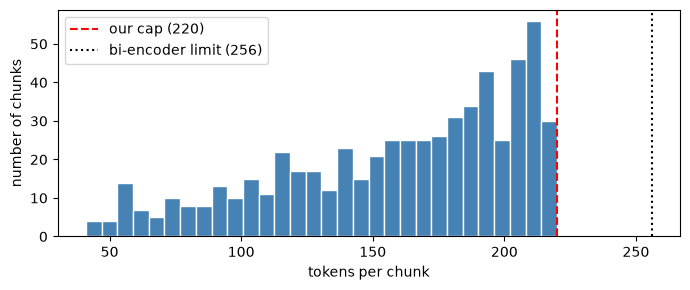


### C0538 | 220 tokens | rules 9.12.4-9.12.4 | pages 87-87
[Netrunner CR v26.03 | 9 Abilities > 9.12 Other Rules and Terminology]
9.12.4. Repeat this process
a. If an ability instructs a player to “repeat this process” without specifying how many times to do so, then that player resolves the ability again, including the instruction to “repeat this process” if it is still applicable.
b. If an ability instructs a player to “repeat this process” a specified number of times, then that player resolves the entire ability, except for the repetition instruction, that many times in a row. The number of repetitions is determined after the first full resolution but before the first repetition, and once the number of repetitions is determined it cannot be changed.
c. Regardless of the number of times an ability is repeated, a checkpoint occurs after each full resolution of the ability’s instructions, before another repetition begins.
d. Each repetition of t

### C0010 | 41 tokens | rules 1.5.1-1.

In [10]:
tokens = [c["n_tokens"] for c in chunks]
print(f"chunks: {len(chunks)} | tokens per chunk: min {min(tokens)}, median {int(np.median(tokens))}, max {max(tokens)}")
print(f"bi-encoder limit: {bi_encoder.max_seq_length} tokens | our cap: {CONFIG['chunk_max_tokens']} | chunks over the cap: {sum(t > CONFIG['chunk_max_tokens'] for t in tokens)}")

# every paragraph of the document must be somewhere in the chunks
all_chunk_text = "\n".join(c["text"] for c in chunks)
missing = [p for u in units for p in u["paras"] if p[:40] not in all_chunk_text]
print("paragraphs missing from the chunks:", len(missing))

print("continuation pieces of long rules:", sum("| continued" in c["text"].split("\n")[0] for c in chunks))
words = r"\b(except|unless|cannot|can't|may not|only if|instead|not allowed|prohibited)\b"
print("chunks with exception / negation wording:", sum(bool(re.search(words, c["text"], re.I)) for c in chunks), "of", len(chunks))

import matplotlib.pyplot as plt
plt.figure(figsize=(7, 3))
plt.hist(tokens, bins=30, color="steelblue", edgecolor="white")
plt.axvline(CONFIG["chunk_max_tokens"], color="red", linestyle="--", label="our cap (220)")
plt.axvline(bi_encoder.max_seq_length, color="black", linestyle=":", label="bi-encoder limit (256)")
plt.xlabel("tokens per chunk"); plt.ylabel("number of chunks"); plt.legend(); plt.tight_layout()
plt.savefig(ROOT / "artifacts/figures/chunk_token_hist.png", dpi=120)
plt.show()

# a few chunks to read
by_size = sorted(chunks, key=lambda c: c["n_tokens"])
samples = [by_size[-1], by_size[0]] + random.Random(CONFIG["seed"]).sample(chunks, 5)
for c in samples:
    print(f"\n### {c['chunk_id']} | {c['n_tokens']} tokens | rules {c['rules']} | pages {c['page_start']}-{c['page_end']}")
    print(c["text"][:900])


### 3.2 Freeze

`chunks.jsonl` and `corpus_manifest.json` (document hash, chunk settings, number of chunks, and the SHA-256 of the chunk file) are written once. All later sections load the chunks with `load_corpus()`, which re-checks that hash. This shows that **both pipelines use exactly the same corpus**. A re-run rebuilds identical chunks.

In [11]:
CHUNKS_PATH = ROOT / "artifacts/chunks.jsonl"
MANIFEST_PATH = ROOT / "artifacts/corpus_manifest.json"

chunks_text = "".join(json.dumps(c, ensure_ascii=False) + "\n" for c in chunks)
chunks_sha256 = hashlib.sha256(chunks_text.encode("utf-8")).hexdigest()

if MANIFEST_PATH.exists():                       # on a re-run, the rebuilt chunks must be identical to the frozen ones
    frozen_hash = json.loads(MANIFEST_PATH.read_text())["chunks_sha256"]
    print("rebuilt corpus identical to the frozen one:", frozen_hash == chunks_sha256)

CHUNKS_PATH.write_text(chunks_text, encoding="utf-8")
MANIFEST_PATH.write_text(json.dumps({
    "document": CONFIG["doc"],
    "body_pages": [FIRST_PAGE, LAST_PAGE],
    "chunk_max_tokens": CONFIG["chunk_max_tokens"],
    "chunk_overlap_tokens": CONFIG["chunk_overlap_tokens"],
    "tokenizer": CONFIG["bi_encoder"],
    "n_chunks": len(chunks),
    "chunks_sha256": chunks_sha256,
}, indent=2) + "\n")

def load_corpus():
    """Every later section loads the chunks through this function, so both pipelines use the same corpus."""
    manifest = json.loads(MANIFEST_PATH.read_text())
    file_hash = hashlib.sha256(CHUNKS_PATH.read_bytes()).hexdigest()
    print("chunks.jsonl matches corpus_manifest.json:", file_hash == manifest["chunks_sha256"])
    return [json.loads(line) for line in CHUNKS_PATH.read_text(encoding="utf-8").splitlines()]

corpus = load_corpus()
print(len(corpus), "chunks | sha256:", chunks_sha256)


rebuilt corpus identical to the frozen one: True
chunks.jsonl matches corpus_manifest.json: True
602 chunks | sha256: abc68239ba744f8090f0b65269e7f540f49ac9998622952a44a5707a79d247b0


## 4. Dense index (Stage 3, Pipeline 1a)

Every chunk is turned into a 384-number vector by the bi-encoder and stored in a FAISS index.
- Vectors are **normalised** (length 1), so the inner product equals the cosine similarity.
- `IndexFlatIP` is an **exact** search. With 602 chunks that is instant and has no approximation error that could confuse the comparison.
- Chunks are embedded exactly as stored, header included, so the bi-encoder sees what the cross-encoder will see.
- The indexing time is measured separately. It happens once, offline, and is **not** part of the per-query latency.

In [12]:
chunk_texts = [c["text"] for c in corpus]

start = time.perf_counter()
embeddings = bi_encoder.encode(chunk_texts, batch_size=32, normalize_embeddings=True, show_progress_bar=False)
indexing_seconds = time.perf_counter() - start

index = faiss.IndexFlatIP(embeddings.shape[1])          # exact search with inner product
index.add(embeddings)
np.save(ROOT / "artifacts/embeddings.npy", embeddings)  # the index can be rebuilt from this file in milliseconds

print("embeddings:", embeddings.shape, embeddings.dtype, "| vectors in the index:", index.ntotal)
print(f"indexing time: {indexing_seconds:.1f} s (done once, offline: not part of the per-query latency)")


embeddings: (602, 384) float32 | vectors in the index: 602
indexing time: 1.5 s (done once, offline: not part of the per-query latency)


### 4.1 Sanity check

If a chunk's own text is used as the query, that chunk must come back first with a cosine close to 1.

In [13]:
# Searching with the exact text of a chunk must return that chunk at rank 1 with a cosine of about 1.0
for i in random.Random(CONFIG["seed"]).sample(range(len(corpus)), 3):
    query_vector = bi_encoder.encode([corpus[i]["text"]], normalize_embeddings=True)
    scores, ids = index.search(query_vector, 1)
    print(f"chunk {corpus[i]['chunk_id']} -> top result {corpus[ids[0][0]]['chunk_id']} | cosine {scores[0][0]:.4f}")


chunk C0114 -> top result C0114 | cosine 1.0000
chunk C0025 -> top result C0025 | cosine 1.0000
chunk C0281 -> top result C0281 | cosine 1.0000


## 5. Retrieval and re-ranking (Stage 4, Pipeline 1b and Pipeline 2a-c)

Two small functions implement the two pipelines:
- **`retrieve(query)`** (Pipeline 1): embed the query, search the index, return the **top 10** chunks by cosine similarity.
- **`rerank(query, hits)`** (Pipeline 2): take **those same 10 candidates**, score all 10 (query, chunk) pairs with the cross-encoder in one batch, and sort by that score, highest first.

Pipeline 1 gives `hits[:3]` to the LLM and Pipeline 2 gives `ranked[:3]`. Both lists come from the same retrieval, so no second search is ever made. The cross-encoder returns a raw score (a logit); it is not turned into a probability.

In [14]:
from dataclasses import dataclass

@dataclass
class Hit:
    chunk_id: str
    bi_rank: int                  # position in the baseline list (1 = best)
    bi_score: float               # cosine similarity from the bi-encoder
    ce_score: float = None        # raw cross-encoder score (filled in by rerank)
    ce_rank: int = None           # position after re-ranking (filled in by rerank)

chunk_by_id = {c["chunk_id"]: c for c in corpus}

def retrieve(query, k=CONFIG["k_retrieve"]):
    """Pipeline 1: embed the query, search the index, return the top k chunks (best first) and the timings."""
    start = time.perf_counter()
    query_vector = bi_encoder.encode([query], normalize_embeddings=True)
    encoded = time.perf_counter()
    scores, ids = index.search(query_vector, k)
    searched = time.perf_counter()

    hits = [Hit(corpus[i]["chunk_id"], rank, float(score))
            for rank, (i, score) in enumerate(zip(ids[0], scores[0]), start=1)]
    return hits, {"encode_ms": (encoded - start) * 1000, "search_ms": (searched - encoded) * 1000}

def rerank(query, hits):
    """Pipeline 2: score all (query, chunk) pairs with the cross-encoder in one batch and sort by that score."""
    start = time.perf_counter()
    pairs = [(query, chunk_by_id[h.chunk_id]["text"]) for h in hits]
    scores = cross_encoder.predict(pairs)
    for h, score in zip(hits, scores):          # the same Hit objects get their score, so the baseline order in the original list is kept
        h.ce_score = float(score)
    ranked = sorted(hits, key=lambda h: (-h.ce_score, h.bi_rank))      # ties keep the bi-encoder order
    for rank, h in enumerate(ranked, start=1):
        h.ce_rank = rank
    return ranked, {"ce_ms": (time.perf_counter() - start) * 1000}

def candidates_table(hits):
    """One row per candidate, in baseline order, with the rank shift."""
    rows = [{"chunk_id": h.chunk_id, "section": chunk_by_id[h.chunk_id]["section_path"].split(" > ")[-1],
             "bi_rank": h.bi_rank, "bi_score": round(h.bi_score, 3),
             "ce_rank": h.ce_rank, "ce_score": round(h.ce_score, 2), "shift": h.bi_rank - h.ce_rank,
             "text": chunk_by_id[h.chunk_id]["text"].split("\n", 1)[1][:110].replace("\n", " ")}
            for h in hits]
    return pd.DataFrame(rows).sort_values("bi_rank")


### 5.1 Demo and checks

One query, with all ten candidates before and after re-ranking. `shift` = baseline rank - re-ranked rank, so a positive number means the chunk moved up. This demo query is only an illustration of the functions; it is not one of the evaluation queries.

In [15]:
query = "What happens if the Corp has to draw a card from R&D but R&D is empty?"

hits, t_retrieve = retrieve(query)             # Pipeline 1: the top 10 by cosine similarity
baseline_top3 = hits[:3]                       # Pipeline 1 gives these three to the LLM

ranked, t_rerank = rerank(query, hits)         # Pipeline 2: the SAME ten candidates, re-sorted by the cross-encoder
reranked_top3 = ranked[:3]                     # Pipeline 2 gives these three to the LLM

print("baseline top 3 :", [h.chunk_id for h in baseline_top3])
print("re-ranked top 3:", [h.chunk_id for h in reranked_top3])
print("retrieval ms:", {k: round(v, 1) for k, v in t_retrieve.items()}, "| re-rank ms:", round(t_rerank["ce_ms"], 1))

pd.set_option("display.max_colwidth", 110, "display.width", 250)
candidates_table(hits)


baseline top 3 : ['C0168', 'C0582', 'C0200']
re-ranked top 3: ['C0168', 'C0582', 'C0583']
retrieval ms: {'encode_ms': 13.1, 'search_ms': 0.1} | re-rank ms: 44.2


,chunk_id,section,bi_rank,bi_score,ce_rank,ce_score,shift,text
0,C0168,4.2 Deck,1,0.582,1,5.28,0,4.2.4. The number of cards in a deck is open information. Any player may count the number of cards in a de...
1,C0582,10.12 Sabotage,2,0.569,2,4.53,0,"10.12.3. In resolving a “sabotage N” effect, the Corp may be required to trash cards from a certain zone i..."
2,C0200,4.8 Set Aside,3,0.520,4,3.28,-1,4.8.7. Facedown cards in the set-aside zone must be kept in distinct groups according to the effect that s...
3,C0583,10.12 Sabotage,4,0.482,3,4.35,1,"b. If there are fewer than N cards in HQ and R&D combined, the Corp trashes all cards from HQ and all card..."
4,C0332,8.3 Arranging and Rearranging Cards,5,0.478,7,1.52,-2,"Example: The Corp plays Cultivate, acting on the top 5 cards of R&D by trashing 1 card, adding 1 card to H..."
5,C0581,10.12 Sabotage,6,0.472,9,-0.35,-3,"Sabotage can be quietly working to undermine a Corp from the inside, organizing protest action, sinking a ..."
6,C0314,7.4 Determining Candidates,7,0.468,6,2.23,1,"Example: The Runner plays The Maker’s Eye and breaches R&D, accessing 2 additional cards. They access Cele..."
7,C0335,8.4 Drawing Cards,8,0.466,5,2.56,3,Example: The Corp takes their mandatory draw while they have Daily Business Show and Raman Rai rezzed. The...
8,C0220,5.6 Steps of the Corp’s Turn,9,0.464,10,-4.78,-1,"5.6.1. During the draw phase, the following steps occur in order: a. The Corp gains their allotted clicks ..."
9,C0311,7.4 Determining Candidates,10,0.462,8,0.06,2,7.4.6. Cards entering a server while a breach is in progress can become candidates. a. If a card enters th...


In [16]:
# Quick checks of the two functions
print("re-ranking returns the same 10 chunks:", sorted(h.chunk_id for h in ranked) == sorted(h.chunk_id for h in hits))
print("re-ranked positions are 1..10 without gaps:", sorted(h.ce_rank for h in ranked) == list(range(1, 11)))

# a query copied from a chunk should bring that chunk to the top
chunk = corpus[300]                            # any chunk will do
hits_2, _ = retrieve(chunk["text"].split("\n", 1)[1])
ranked_2, _ = rerank(chunk["text"].split("\n", 1)[1], hits_2)
print(f"query copied from {chunk['chunk_id']} -> baseline rank 1: {hits_2[0].chunk_id} | re-ranked rank 1: {ranked_2[0].chunk_id}")

print("longest chunk:", max(c["n_tokens"] for c in corpus), "tokens, so a (query, chunk) pair stays far below the cross-encoder limit of 512")


re-ranking returns the same 10 chunks: True
re-ranked positions are 1..10 without gaps: True
query copied from C0300 -> baseline rank 1: C0300 | re-ranked rank 1: C0300
longest chunk: 220 tokens, so a (query, chunk) pair stays far below the cross-encoder limit of 512


## 6. Prompt and generation (Stage 5, Pipeline 1c and Pipeline 2d)

**LLM:** Gemini through the Google AI Studio free tier, model `gemini-3.1-flash-lite` (pinned in `CONFIG`), `temperature = 0`, hidden reasoning set to `MINIMAL`.
- *Why this model:* the larger `gemini-3.6-flash` allows only **20 requests per day** on the free tier, which is too few for 23 queries × 2 answers plus latency measurements. Flash-Lite has a higher free limit. The same model is used for both pipelines, so the comparison stays fair.
- *Why `MINIMAL` reasoning:* Gemini 3.x models can "think" before answering, which makes calls slower and spends the output limit on hidden reasoning. With `MINIMAL`, the whole output limit is used for the answer and answers are more predictable.

**Fair comparison:** both pipelines use **one** `build_prompt()`, the same model, the same temperature and the same output limit. The two prompts differ **only** in which three passages fill the slots `[S1]`-`[S3]`. Passages are listed best first, using each pipeline's own ranking.

The prompt follows the grounded-generation pattern from the lectures: an instruction, labelled evidence, a refusal rule for when the passages do not contain the answer, a citation rule, and the question last.

In [17]:
PROMPT_TEMPLATE = """You answer questions about the Netrunner Comprehensive Rules using ONLY the numbered passages below.
- Put the passage id after every claim, like [S2].
- If the passages do not contain the answer, reply exactly: "The provided passages do not cover this."
- If a passage states an exception, condition or restriction that is relevant to the question, include it.
- Do not use outside knowledge.

PASSAGES:
{passages}

QUESTION: {question}
ANSWER:"""

def build_prompt(question, chunk_ids):
    """The ONE prompt used by both pipelines. Only the three passages (and their order) differ."""
    passages = []
    for number, chunk_id in enumerate(chunk_ids, start=1):
        chunk = chunk_by_id[chunk_id]
        pages = chunk["page_start"] if chunk["page_start"] == chunk["page_end"] else f"{chunk['page_start']}-{chunk['page_end']}"
        body = chunk["text"].split("\n", 1)[1]                    # the header is replaced by the section path below
        passages.append(f"[S{number}] ({chunk['section_path']}, p.{pages}) {body}")
    return PROMPT_TEMPLATE.format(passages="\n".join(passages), question=question)


### 6.1 Calling Gemini, with a cache

`call_gemini()` makes one real call and retries when Google is busy. `generate()` first looks in a cache file (`artifacts/llm_cache.jsonl`). By default, `allow_live_llm_calls` is `False`, so a re-run is network-free and uses only cached answers; set it to `True` deliberately when creating missing answers. The latency section (Section 10) calls `call_gemini()` directly only when a fresh timing is explicitly requested.

The API key is read from `.env`; it is not in the code or in any output.

In [18]:
from google import genai
from google.genai import types, errors

client = None  # Created lazily, so an offline cached rerun needs neither a Gemini key nor network access.

def call_gemini(prompt):
    """One real call to Gemini. Returns (answer, seconds). Waits and retries when Google is busy (503) or rate-limited (429)."""
    if not CONFIG["allow_live_llm_calls"]:
        raise RuntimeError("Live LLM calls are disabled. Set CONFIG['allow_live_llm_calls'] = True to create missing cached answers.")
    api_key = os.getenv("GEMINI_API_KEY")
    if not api_key:
        raise RuntimeError("GEMINI_API_KEY is required only when allow_live_llm_calls is True.")
    global client
    if client is None:
        client = genai.Client(api_key=api_key)
    config = types.GenerateContentConfig(
        temperature=CONFIG["temperature"],
        max_output_tokens=CONFIG["max_output_tokens"],
        thinking_config=types.ThinkingConfig(thinking_level=CONFIG["thinking_level"]),   # no hidden reasoning, so answers are short and fast
    )
    for attempt in range(1, 7):
        try:
            start = time.perf_counter()
            response = client.models.generate_content(model=CONFIG["llm_model"], contents=prompt, config=config)
            return (response.text or "").strip(), time.perf_counter() - start
        except errors.APIError as error:
            if error.code not in (429, 500, 503) or attempt == 6:
                raise
            print(f"Gemini busy or rate-limited (error {error.code}), retrying in {10 * attempt} s ...")
            time.sleep(10 * attempt)

# Answers are cached on disk: the same prompt is never sent twice, so re-running the notebook is free and gives identical answers.
CACHE_PATH = ROOT / "artifacts/llm_cache.jsonl"
cache = {}
if CACHE_PATH.exists():
    for line in CACHE_PATH.read_text(encoding="utf-8").splitlines():
        row = json.loads(line)
        cache[row["key"]] = row["answer"]

def cache_key(prompt):
    return hashlib.sha256(f"{CONFIG['llm_model']}|{CONFIG['temperature']}|{CONFIG['thinking_level']}|{prompt}".encode()).hexdigest()

def generate(prompt):
    """Return a cached answer, or (only when explicitly enabled) request and cache one."""
    key = cache_key(prompt)
    if key not in cache:
        answer, _ = call_gemini(prompt)
        cache[key] = answer
        with open(CACHE_PATH, "a", encoding="utf-8") as f:
            f.write(json.dumps({"key": key, "model": CONFIG["llm_model"], "answer": answer}, ensure_ascii=False) + "\n")
    return cache[key]

print("model:", CONFIG["llm_model"], "| temperature:", CONFIG["temperature"], "| thinking:", CONFIG["thinking_level"], "| cached answers:", len(cache))
smoke_prompt = "Reply with OK"
if cache_key(smoke_prompt) in cache:
    print("cached smoke answer ->", cache[cache_key(smoke_prompt)])
else:
    print("smoke call skipped: its answer is not cached (offline replay stays network-free).")


model: gemini-3.1-flash-lite | temperature: 0.0 | thinking: MINIMAL | cached answers: 58
cached smoke answer -> OK


### 6.2 Running both pipelines on one query

`run_query()` retrieves the top 10, builds Answer 1 from the top 3 as ranked by the bi-encoder, re-ranks the same 10 for Answer 2, and saves everything (all 10 candidates with both ranks and scores, both prompts, both answers, timings) in `artifacts/results/<qid>.json`. The three queries below only demonstrate that it works.

In [19]:
from dataclasses import asdict

def run_query(qid, question, category=None, gold=None, out_dir=ROOT / "artifacts/results"):
    """Run BOTH pipelines on one question and save everything to <out_dir>/<qid>.json."""
    hits, t_retrieve = retrieve(question)                   # Pipeline 1: top 10 by cosine similarity
    baseline_ids = [h.chunk_id for h in hits[:CONFIG["k_final"]]]

    ranked, t_rerank = rerank(question, hits)               # Pipeline 2: the same 10, re-sorted by the cross-encoder
    reranked_ids = [h.chunk_id for h in ranked[:CONFIG["k_final"]]]

    prompt_1 = build_prompt(question, baseline_ids)
    prompt_2 = build_prompt(question, reranked_ids)
    result = {
        "qid": qid, "query": question, "category": category, "gold": gold,
        "corpus_sha256": json.loads(MANIFEST_PATH.read_text())["chunks_sha256"],
        "candidates": [asdict(h) for h in hits],            # all 10: baseline rank and score, re-ranked rank and score
        "baseline": {"top3": baseline_ids, "prompt": prompt_1, "answer": generate(prompt_1)},
        "reranked": {"top3": reranked_ids, "prompt": prompt_2, "answer": generate(prompt_2)},
        "timings_ms": {**t_retrieve, **t_rerank},
    }
    out_dir.mkdir(parents=True, exist_ok=True)
    (out_dir / f"{qid}.json").write_text(json.dumps(result, indent=2, ensure_ascii=False), encoding="utf-8")
    return result


In [20]:
# Three illustration queries (NOT the evaluation queries). Their files go to artifacts/results/demo/.
demo_queries = [
    ("D1", "Can the Runner jack out during an encounter with ice?"),
    ("D2", "What does it mean for the Corp to rez a card?"),
    ("D3", "Who wins if the Corp must draw a card from R&D and R&D is empty?"),
]
for qid, question in demo_queries:
    result = run_query(qid, question, out_dir=ROOT / "artifacts/results/demo")
    print("=" * 100)
    print(qid, question)
    print("baseline top 3 :", result["baseline"]["top3"], "| re-ranked top 3:", result["reranked"]["top3"])
    print("\nAnswer 1 (baseline):\n" + result["baseline"]["answer"])
    print("\nAnswer 2 (re-ranked):\n" + result["reranked"]["answer"])


D1 Can the Runner jack out during an encounter with ice?
baseline top 3 : ['C0236', 'C0265', 'C0232'] | re-ranked top 3: ['C0265', 'C0266', 'C0258']

Answer 1 (baseline):
The provided passages do not cover this.

Answer 2 (re-ranked):
The provided passages do not cover this.
D2 What does it mean for the Corp to rez a card?
baseline top 3 : ['C0353', 'C0320', 'C0319'] | re-ranked top 3: ['C0320', 'C0353', 'C0319']

Answer 1 (baseline):
To rez an unrezzed card is to turn it faceup [S3]. To resolve the process, the Corp pays the card's rez cost (accounting for any modifiers or additional costs), a checkpoint occurs, and then the Corp turns the card faceup [S2]. For the purposes of meeting trigger conditions, the card is considered to be rezzed at the conclusion of this process [S2]. Before rezzing, the Corp must pay the rez cost, though card abilities can modify or ignore these costs if they state so explicitly [S3d]. Note that agendas cannot be rezzed [S3c].

Answer 2 (re-ranked):
To rez

## 7. Query set (Stage 6): finding failure queries

**Goal:** a labelled query set that includes failure queries for every category the assignment names (keyword trap, exception, negation, chunk buried at rank 4-10), plus ordinary control queries.

**Process**
1. **48 candidate queries** were written from the rules text in player language (`queries/queries.yaml`): 10 control, 10 negation, 8 buried, 7 exception and 13 keyword trap (a first round of 6, then 7 more because the first round found no keyword trap that re-ranking fixed).
2. For each, the **gold chunk** (the chunk that answers it) was first found by searching the rules text for the rule itself, **not** by looking at what either retriever returned.
3. Retrieval and re-ranking (no LLM, so it is cheap) are run on every candidate, and the position of the gold chunk is compared before and after re-ranking.
4. The labels were then **audited** (Section 7.2), because a rulebook often states the same rule in more than one place.
5. The whole candidate table is kept, including the queries where re-ranking made no difference or made things worse. The hit rate is part of an honest result.

**From here on, nothing in the pipeline may be changed** (chunking, models, `k`, prompt). Queries are never edited to make a pipeline look better.

> The gold labels were **proposed by Claude**. The 23 final queries were then reviewed against the rule text by Claude, at the student's request, and each got an `expected_answer`. One draft answer was corrected (Q03); no gold label changed.

In [21]:
import yaml

queries = yaml.safe_load((ROOT / "queries/queries.yaml").read_text(encoding="utf-8"))
candidates_df = pd.DataFrame(queries)
print(len(queries), "candidate queries")
candidates_df.groupby("category").size().to_frame("queries")


48 candidate queries


,queries
category,
buried,8
control,10
exception,7
keyword_trap,13
negation,10


### 7.1 Mining: where does the gold chunk land?

For each query, the best-placed essential gold chunk is looked up in the baseline top 10 and in the re-ranked order. When several chunks are essential, **any one of them answers the question**, so the best-placed one counts.

| Result | Meaning |
|---|---|
| `fixed_by_rerank` | gold at rank 4-10 for the baseline, and in the top 3 after re-ranking |
| `both_ok` | gold in the top 3 both times |
| `hurt_by_rerank` | gold in the top 3 for the baseline, but pushed out by re-ranking |
| `both_fail` | gold in the top 10, but outside the top 3 both times (a ranking failure) |
| `recall_ceiling` | gold not in the top 10 at all: the re-ranker only reorders those 10, so it cannot help |

In [22]:
def classify(bi_rank, ce_rank):
    """Where did the best gold chunk land before and after re-ranking? (rank = None means not in the top 10)"""
    if bi_rank is None:
        return "recall_ceiling"            # not in the top 10: re-ranking cannot help
    if bi_rank > 3 and ce_rank <= 3:
        return "fixed_by_rerank"           # outside the top 3 before, inside after
    if bi_rank <= 3 and ce_rank <= 3:
        return "both_ok"
    if bi_rank <= 3 and ce_rank > 3:
        return "hurt_by_rerank"
    return "both_fail"                     # in the top 10, but outside the top 3 both times

rows = []
for q in queries:
    hits, _ = retrieve(q["query"])
    ranked, _ = rerank(q["query"], hits)
    gold = [h for h in hits if h.chunk_id in q["gold_essential"]]      # gold chunks that are in the top 10
    best = min(gold, key=lambda h: h.bi_rank) if gold else None        # the best-placed one before re-ranking
    best_ce = min(gold, key=lambda h: h.ce_rank) if gold else None     # the best-placed one after re-ranking
    bi_rank = best.bi_rank if best else None
    ce_rank = best_ce.ce_rank if best_ce else None
    rows.append({"qid": q["qid"], "category": q["category"], "gold_bi_rank": bi_rank, "gold_ce_rank": ce_rank,
                 "result": classify(bi_rank, ce_rank), "query": q["query"]})

mining = pd.DataFrame(rows).astype({"gold_bi_rank": "Int64", "gold_ce_rank": "Int64"})   # whole numbers, <NA> when not in the top 10
mining.to_csv(ROOT / "artifacts/candidate_mining.csv", index=False)
mining.drop(columns="query")


,qid,category,gold_bi_rank,gold_ce_rank,result
0,Q01,control,1,2,both_ok
1,Q02,control,7,1,fixed_by_rerank
2,Q03,control,1,1,both_ok
3,Q04,control,2,1,both_ok
4,Q05,control,1,1,both_ok
5,Q06,control,1,1,both_ok
6,Q07,control,1,1,both_ok
7,Q08,control,1,1,both_ok
8,Q09,control,1,1,both_ok
9,Q10,control,<NA>,<NA>,recall_ceiling


In [23]:
print("Result of re-ranking on all", len(mining), "candidate queries (gold chunk placement):")
print(mining["result"].value_counts().to_string())
print()
pd.crosstab(mining["category"], mining["result"])


Result of re-ranking on all 48 candidate queries (gold chunk placement):
result
both_ok            35
fixed_by_rerank     4
recall_ceiling      4
hurt_by_rerank      3
both_fail           2



result,both_fail,both_ok,fixed_by_rerank,hurt_by_rerank,recall_ceiling
category,,,,,
buried,1,4,2,1,0
control,0,8,1,0,1
exception,0,6,0,0,1
keyword_trap,0,10,1,1,1
negation,1,7,0,1,1


### 7.2 Label audit and the final query set

**Why an audit was needed.** The first labels named the one rule the query was written from. But a rulebook often states the same thing in several places (for example, the 7-point win appears in rules 1.7.2a, 1.17.2 and 10.3.1c). If such a second chunk is in the top 3 but not labelled, the table above would wrongly call the baseline a failure.

**How it was done (pooled judgement).** For every query whose result was not `both_ok`, **all 10 candidate chunks were read** and each was judged against one question: *does this chunk, on its own, fully answer the query?* Both pipelines rank exactly these 10 chunks, so judging all of them is fair to both. Adding a missed gold chunk can never turn a `both_ok` result into anything else, so those queries did not need this check. Chunks that only partly answer were recorded as *supporting* and do not count.

**What changed** (all from reading the rule text):

| Query | Added as essential gold | Effect |
|---|---|---|
| Q01 | C0096 (1.17.2), C0552 (10.3.1c) | the baseline already had an answer at rank 1: no longer a "fix" |
| Q15 | C0053 (1.13.6d) | the baseline already had an answer at rank 2: no longer a "fix" |
| Q27 | C0032 (1.10.3b) | the baseline already had an answer at rank 1: no longer a "fix" |
| Q04 | C0256 (6.4.3), C0281 (6.9.2b), C0597 (appendix) | the answer was in the top 3: not a recall-ceiling case |
| Q33 | C0218 (5.5.4c), C0225 (5.7.2a), C0202 (5.1.3) | the answer was in the top 3: not a recall-ceiling case |
| Q29 | C0320 (8.1.2e) | the answer was at rank 4, re-ranked to 1: a genuine fix |
| Q23, Q28, Q32, Q36, Q42 | one more chunk each that restates the rule | result unchanged, except Q28 which became `both_ok` |

Three queries that looked like fixes (Q01, Q15, Q27) turned out not to be. This is reported here so that the remaining fixes can be trusted.

**Final set (23 queries).** Selection rule, fixed before any LLM answer was generated:
- every query where re-ranking changed the outcome: all `fixed_by_rerank`, all `hurt_by_rerank` and all `both_fail`;
- two `recall_ceiling` queries (one exception, one keyword trap) to show the limit of re-ranking;
- the remaining queries are `both_ok` controls that cover every category.

In [24]:
final_ids = [q["qid"] for q in queries if q["final"]]
final_df = mining[mining["qid"].isin(final_ids)]
print(len(final_ids), "final queries out of", len(queries), "candidates")
pd.crosstab(final_df["category"], final_df["result"])


23 final queries out of 48 candidates


result,both_fail,both_ok,fixed_by_rerank,hurt_by_rerank,recall_ceiling
category,,,,,
buried,1,1,2,1,0
control,0,5,1,0,0
exception,0,2,0,0,1
keyword_trap,0,2,1,1,1
negation,1,2,0,1,0


## 8. Results (Stage 7): both pipelines on the 23 final queries

Every final query goes through `run_query()`: Pipeline 1 sends the bi-encoder's top 3 to Gemini (**Answer 1**), Pipeline 2 sends the cross-encoder's top 3 of the **same** 10 candidates (**Answer 2**). All ten candidates, both prompts and both answers are saved per query in `artifacts/results/<qid>.json`.

In [25]:
final_queries = [q for q in queries if q["final"]]
query_by_id = {q["qid"]: q for q in queries}
result_of = dict(zip(mining["qid"], mining["result"]))         # mining result (fixed_by_rerank, both_ok, ...)

# Both pipelines on every final query. Answers come from the cache when the prompt was seen before.
results = {}
for q in final_queries:
    results[q["qid"]] = run_query(q["qid"], q["query"], q["category"], q["gold_essential"])

same = sum(r["baseline"]["top3"] == r["reranked"]["top3"] for r in results.values())
print(len(results), "queries run, results saved in artifacts/results/<qid>.json")
print("queries where both pipelines sent the same 3 passages in the same order:", same)
print("every result was made from the frozen corpus:",
      all(r["corpus_sha256"] == json.loads(MANIFEST_PATH.read_text())["chunks_sha256"] for r in results.values()))


23 queries run, results saved in artifacts/results/<qid>.json
queries where both pipelines sent the same 3 passages in the same order: 1
every result was made from the frozen corpus: True


### 8.1 Retrieval metrics

Computed on the **essential** gold chunks only (Section 7):
- **Hit@3**: is at least one essential gold chunk among the 3 passages the LLM gets? (any one of them answers the question)
- **Recall@3**: the share of the essential gold chunks that are in the top 3.
- **MRR@10**: the average of 1 / rank of the best gold chunk (0 when no gold chunk is in the top 10).
- **Mean gold rank**: the average rank of the best gold chunk, only over queries where it is in the top 10.

Note that the final set was **chosen** to contain every query where re-ranking made a difference, plus controls. These numbers describe this set, not the average behaviour of the two pipelines on random questions.

In [26]:
def gold_ranks(result, rank_key):
    """Ranks (1-10) of the essential gold chunks that are in the top 10, best first."""
    return sorted(c[rank_key] for c in result["candidates"] if c["chunk_id"] in result["gold"])

rows = []
for qid, r in results.items():
    for pipeline, rank_key in [("P1 baseline", "bi_rank"), ("P2 re-rank", "ce_rank")]:
        ranks = gold_ranks(r, rank_key)
        rows.append({"qid": qid, "category": r["category"], "pipeline": pipeline,
                     "hit@3": int(bool(ranks) and ranks[0] <= 3),              # any essential gold chunk in the top 3
                     "recall@3": sum(x <= 3 for x in ranks) / len(r["gold"]),   # share of essential gold chunks in the top 3
                     "rr@10": 1 / ranks[0] if ranks else 0.0,                  # 1 / rank of the best gold chunk (0 if not in the top 10)
                     "gold_rank": ranks[0] if ranks else None})
metrics = pd.DataFrame(rows).astype({"gold_rank": "Int64"})
metrics.to_csv(ROOT / "artifacts/metrics.csv", index=False)

overall = metrics.groupby("pipeline").agg(**{"Hit@3": ("hit@3", "mean"), "Recall@3": ("recall@3", "mean"),
                                             "MRR@10": ("rr@10", "mean"), "mean gold rank (in top 10)": ("gold_rank", "mean")})
print("All", len(results), "final queries (essential gold only):")
overall.round(3)


All 23 final queries (essential gold only):


,Hit@3,Recall@3,MRR@10,mean gold rank (in top 10)
pipeline,,,,
P1 baseline,0.652,0.514,0.637,2.286
P2 re-rank,0.696,0.638,0.687,2.238


In [27]:
by_category = metrics.pivot_table(index="category", columns="pipeline", values=["hit@3", "rr@10"], aggfunc="mean").round(2)
by_category.columns = [f"{m} {p.split()[0]}" for m, p in by_category.columns]
by_category.insert(0, "queries", metrics[metrics.pipeline == "P1 baseline"].groupby("category").size())

# Wins / ties / losses of Pipeline 2 against Pipeline 1, compared on the rank of the best gold chunk
p1 = metrics[metrics.pipeline == "P1 baseline"].set_index("qid")["rr@10"]
p2 = metrics[metrics.pipeline == "P2 re-rank"].set_index("qid")["rr@10"]
print("Re-ranking moved the best gold chunk  up:", int((p2 > p1).sum()),
      "| same rank:", int((p2 == p1).sum()), "| down:", int((p2 < p1).sum()))
print("Outcome per query:", dict(collections.Counter(result_of[q] for q in results)))
by_category


Re-ranking moved the best gold chunk  up: 5 | same rank: 12 | down: 6
Outcome per query: {'both_ok': 12, 'fixed_by_rerank': 4, 'recall_ceiling': 2, 'both_fail': 2, 'hurt_by_rerank': 3}


,queries,hit@3 P1,hit@3 P2,rr@10 P1,rr@10 P2
category,,,,,
buried,5,0.40,0.60,0.55,0.66
control,6,0.83,1.00,0.86,0.92
exception,3,0.67,0.67,0.50,0.67
keyword_trap,5,0.60,0.60,0.42,0.52
negation,4,0.75,0.50,0.79,0.60


### 8.2 Rank-shift table

One row per query where the outcome is not "gold in the top 3 both times": the spec's *"Chunk X moved from rank #8 to rank #1"*. Ranks are written `#bi-encoder rank -> #cross-encoder rank`. The last two columns show which chunks lost and won a place among the three passages given to the LLM. Saved as `artifacts/rank_shift.csv`.

In [28]:
def rule_label(chunk_id):
    """'C0320 (8.1.2)': chunk id with the rule range it contains."""
    first, last = chunk_by_id[chunk_id]["rules"].split("-")
    return f"{chunk_id} ({first if first == last else first + '-' + last})"

failure_ids = [qid for qid in results if result_of[qid] != "both_ok"]     # every query where the outcome is not "both fine"

rows = []
for qid in failure_ids:
    r = results[qid]
    gold = [c for c in r["candidates"] if c["chunk_id"] in r["gold"]]
    shifts = ", ".join(f"{rule_label(c['chunk_id'])} #{c['bi_rank']} -> #{c['ce_rank']}" for c in gold) or "not in the top 10"
    pushed_out = [c for c in r["baseline"]["top3"] if c not in r["reranked"]["top3"]]
    pulled_in = [c for c in r["reranked"]["top3"] if c not in r["baseline"]["top3"]]
    rows.append({"qid": qid, "category": r["category"], "result": result_of[qid], "gold chunk: bi-rank -> CE-rank": shifts,
                 "left the top 3": ", ".join(map(rule_label, pushed_out)), "entered the top 3": ", ".join(map(rule_label, pulled_in))})
rank_shift = pd.DataFrame(rows).sort_values(["result", "qid"])
rank_shift.to_csv(ROOT / "artifacts/rank_shift.csv", index=False)
pd.set_option("display.max_colwidth", 120)
rank_shift


,qid,category,result,gold chunk: bi-rank -> CE-rank,left the top 3,entered the top 3
2,Q18,negation,both_fail,C0002 (1.2.1-1.2.4) #6 -> #6,"C0521 (9.12.1), C0085 (1.16.4), C0208 (5.2.3-5.2.4)","C0500 (9.9.11), C0535 (9.12.3), C0534 (9.12.3)"
6,Q34,buried,both_fail,C0311 (7.4.6) #4 -> #5,"C0293 (7.3.1), C0305 (7.4.2)","C0296 (7.3.4), C0295 (7.3.4)"
0,Q02,control,fixed_by_rerank,C0210 (5.2.6) #7 -> #1,"C0220 (5.6.1), C0213 (5.4.1-5.4.2)","C0210 (5.2.6), C0208 (5.2.3-5.2.4)"
4,Q29,keyword_trap,fixed_by_rerank,C0320 (8.1.2) #4 -> #1,"C0054 (1.13.7-1.13.8), C0323 (8.1.4)","C0320 (8.1.2), C0338 (8.5.2)"
7,Q35,buried,fixed_by_rerank,C0313 (7.4.7) #4 -> #1,"C0168 (4.2.4-4.2.7), C0317 (7.5.1-7.5.7), C0044 (1.12.3)","C0313 (7.4.7), C0315 (7.4.7), C0316 (7.4.7)"
9,Q41,buried,fixed_by_rerank,C0301 (7.3.7-7.3.8) #4 -> #1,"C0138 (3.2.1-3.2.2), C0098 (1.17.3), C0099 (1.17.4-1.17.7)","C0301 (7.3.7-7.3.8), C0290 (7.1.6-7.1.8), C0100 (1.17.8)"
3,Q23,negation,hurt_by_rerank,"C0153 (3.8.5) #1 -> #7, C0552 (10.3.1) #8 -> #4",C0153 (3.8.5),C0152 (3.8.1-3.8.4)
5,Q32,keyword_trap,hurt_by_rerank,C0168 (4.2.4-4.2.7) #3 -> #4,"C0222 (5.6.3), C0168 (4.2.4-4.2.7)","C0335 (8.4.3), C0313 (7.4.7)"
8,Q36,buried,hurt_by_rerank,C0317 (7.5.1-7.5.7) #1 -> #9,"C0317 (7.5.1-7.5.7), C0307 (7.4.2)","C0295 (7.3.4), C0308 (7.4.3)"
1,Q12,exception,recall_ceiling,not in the top 10,"C0200 (4.8.7), C0182 (4.6.5), C0180 (4.6.4)","C0328 (8.2.7-8.2.10), C0048 (1.13.1-1.13.2), C0023 (1.8.3)"


### 8.3 Bump charts and score scatter

Each bump chart shows the same 10 candidates: their rank by the bi-encoder (left) and by the cross-encoder (right). The scatter plot shows every candidate of every final query with both scores; points far from a common trend are chunks the two models disagree on.

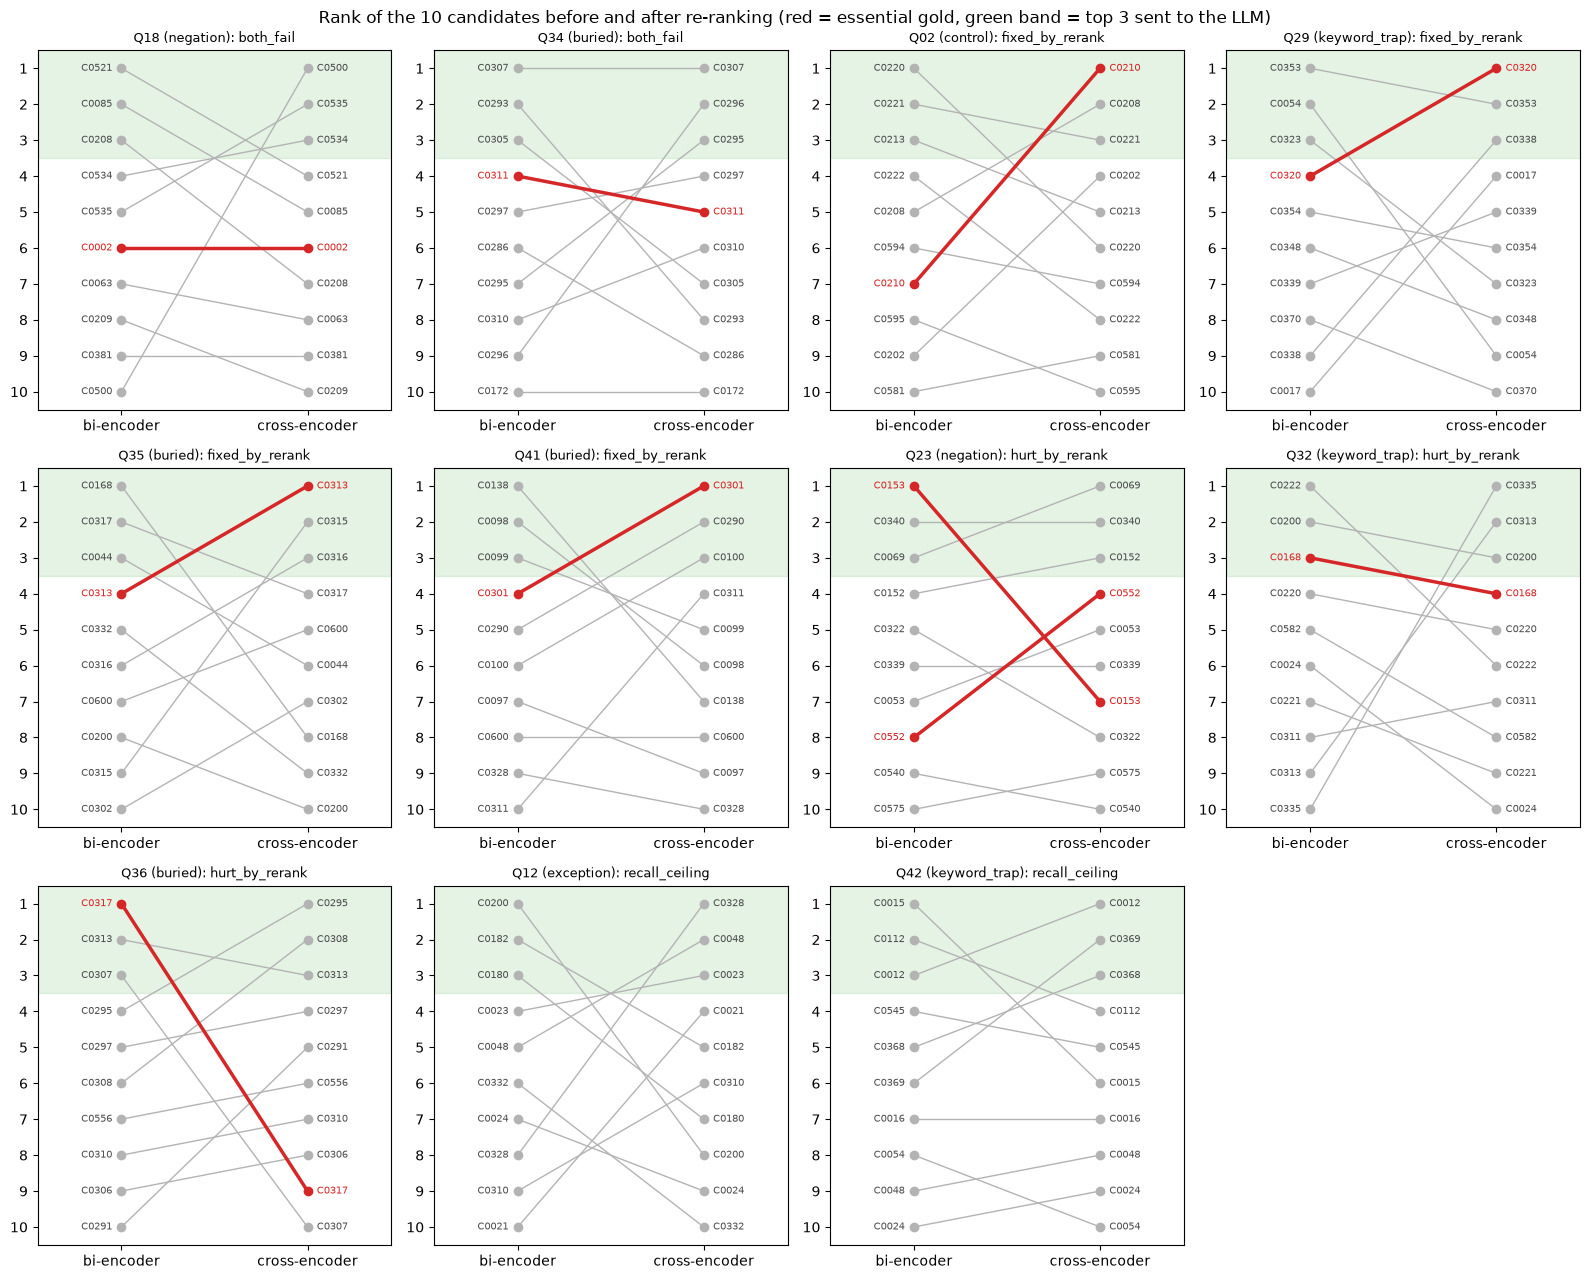

In [29]:
import matplotlib.pyplot as plt

def bump_chart(qid, ax):
    """Left: baseline rank, right: re-ranked rank, for all 10 candidates. Gold in red, top-3 band shaded."""
    r = results[qid]
    ax.axhspan(0.5, 3.5, color="tab:green", alpha=0.12)                 # what the LLM gets
    for c in r["candidates"]:
        is_gold = c["chunk_id"] in r["gold"]
        ax.plot([0, 1], [c["bi_rank"], c["ce_rank"]], "-o", color="tab:red" if is_gold else "0.7",
                lw=2.5 if is_gold else 1, zorder=3 if is_gold else 2)
        ax.text(-0.05, c["bi_rank"], c["chunk_id"], ha="right", va="center", fontsize=7, color="tab:red" if is_gold else "0.3")
        ax.text(1.05, c["ce_rank"], c["chunk_id"], ha="left", va="center", fontsize=7, color="tab:red" if is_gold else "0.3")
    ax.set_xlim(-0.45, 1.45); ax.set_ylim(10.5, 0.5)
    ax.set_xticks([0, 1], ["bi-encoder", "cross-encoder"]); ax.set_yticks(range(1, 11))
    ax.set_title(f"{qid} ({r['category']}): {result_of[qid]}", fontsize=9)

# The overview is deliberately limited to outcome-changing cases: four fixes and three regressions.
# The remaining failure queries retain their individual evidence-pack charts below.
overview_ids = [qid for qid in failure_ids if result_of[qid] in {"fixed_by_rerank", "hurt_by_rerank"}]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax in axes.flat[len(overview_ids):]:
    ax.axis("off")
for qid, ax in zip(sorted(overview_ids, key=lambda q: (result_of[q], q)), axes.flat):
    bump_chart(qid, ax)
fig.suptitle("Rank shifts for outcome-changing queries (red = essential gold, green band = top 3 sent to the LLM)")
fig.tight_layout()
fig.savefig(ROOT / "artifacts/figures/bump_charts.png", dpi=110)
plt.show()


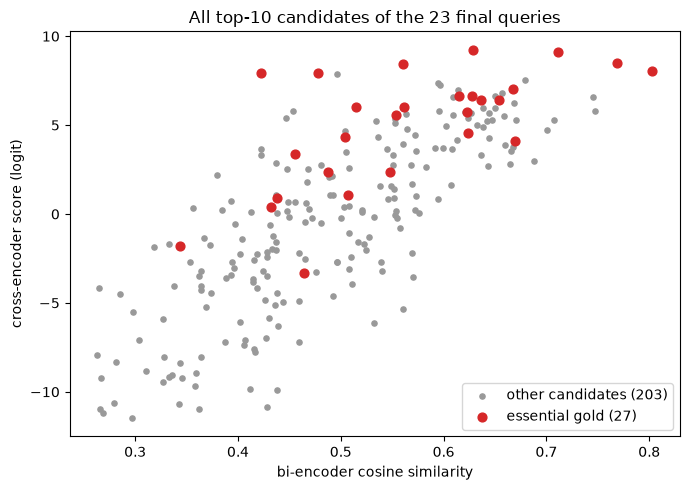

rank agreement between the two models within one query (Spearman): median 0.38, min -0.20, max 0.94


In [30]:
points = pd.DataFrame([{**c, "gold": c["chunk_id"] in r["gold"]} for r in results.values() for c in r["candidates"]])

fig, ax = plt.subplots(figsize=(7, 5))
other, gold = points[~points.gold], points[points.gold]
ax.scatter(other.bi_score, other.ce_score, s=14, color="0.6", label=f"other candidates ({len(other)})")
ax.scatter(gold.bi_score, gold.ce_score, s=40, color="tab:red", label=f"essential gold ({len(gold)})")
ax.set_xlabel("bi-encoder cosine similarity"); ax.set_ylabel("cross-encoder score (logit)")
ax.set_title(f"All top-10 candidates of the {len(results)} final queries")
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "artifacts/figures/score_scatter.png", dpi=110)
plt.show()

# How strongly do the two models agree on the order of the same 10 chunks? (Spearman correlation per query)
rho = []
for r in results.values():
    ranks = pd.DataFrame(r["candidates"])
    rho.append(ranks["bi_rank"].corr(ranks["ce_rank"], method="spearman"))
print(f"rank agreement between the two models within one query (Spearman): median {np.median(rho):.2f}, "
      f"min {min(rho):.2f}, max {max(rho):.2f}")


### 8.4 Answer comparison

Each answer was compared with the query's `expected_answer` and with the three passages it was given. The labels are stored in `queries/answer_labels.yaml` (with a note per query):

| Label | Meaning |
|---|---|
| `correct` | matches the expected answer for what the question asks, including the conditions that change the answer |
| `omits_clause` | right in general, but misses an exception, restriction or penalty |
| `misstates` | states the wrong rule, for example inverts a negation |
| `hallucinated` | makes a claim that none of its three passages supports |
| `refused` | "The provided passages do not cover this." |

Citation faithfulness is recorded separately: `ok` (every `[S#]` supports its claim), `partly`, `unsupported`, or `n/a` for a refusal.



In [31]:
label_file = yaml.safe_load((ROOT / "queries/answer_labels.yaml").read_text(encoding="utf-8"))
labels = {row["qid"]: row for row in label_file["labels"]}

answers = pd.DataFrame([{"qid": qid, "category": r["category"], "result": result_of[qid],
                         "Answer 1": labels[qid]["answer1"], "Answer 2": labels[qid]["answer2"],
                         "citations 1": labels[qid]["citations1"], "citations 2": labels[qid]["citations2"]}
                        for qid, r in results.items()])
label_counts = pd.DataFrame({"Answer 1 (baseline)": answers["Answer 1"].value_counts(),
                             "Answer 2 (re-ranked)": answers["Answer 2"].value_counts()}).fillna(0).astype(int)
display(label_counts)

changed = answers[answers["Answer 1"] != answers["Answer 2"]]
print(f"Queries where the two answers got a different label ({len(changed)}):")
changed


,Answer 1 (baseline),Answer 2 (re-ranked)
correct,15,16
refused,7,6
hallucinated,1,1


Queries where the two answers got a different label (7):


,qid,category,result,Answer 1,Answer 2,citations 1,citations 2
1,Q02,control,fixed_by_rerank,refused,correct,n/a,ok
11,Q23,negation,hurt_by_rerank,correct,refused,ok,n/a
14,Q29,keyword_trap,fixed_by_rerank,refused,correct,n/a,ok
16,Q32,keyword_trap,hurt_by_rerank,correct,refused,ok,n/a
18,Q35,buried,fixed_by_rerank,refused,correct,n/a,ok
19,Q36,buried,hurt_by_rerank,correct,refused,ok,n/a
21,Q41,buried,fixed_by_rerank,refused,correct,n/a,ok


## 9. Failure analysis: one evidence pack per query

Every query whose result is not "gold in the top 3 both times" gets an evidence pack: the 10 candidates with both ranks, the bump chart, the passages each pipeline sent to the LLM, both answers with their labels, and a **stage diagnosis** (Tutorial s16), which names the stage that failed:
- **chunking**: the answer is split or hidden inside an unrelated chunk;
- **retrieval_recall**: the gold chunk is not in the top 10, so no re-ranker can help;
- **ranking**: the gold chunk is in the top 10 but is not ranked in the top 3;
- **generation**: the right passage was given, but the answer is wrong.

Order: fixed by re-ranking, hurt by re-ranking, both fail, recall ceiling.

In [32]:
import textwrap

def wrap(text, indent="    "):
    """Wrap long lines for printing, keeping the answer's own line breaks."""
    return "\n".join(textwrap.fill(line, 110, initial_indent=indent, subsequent_indent=indent) for line in text.splitlines())

def evidence_pack(qid):
    """Everything about one query: candidates, bump chart, both top 3s, both answers, labels and diagnosis."""
    r, label = results[qid], labels[qid]
    print(f"{qid} ({r['category']}): {r['query']}")
    print(f"Result: {result_of[qid]} | stage: {label['stage']}")
    print("Expected answer:\n" + wrap(query_by_id[qid]["expected_answer"]))

    table = candidates_table([Hit(**c) for c in r["candidates"]])
    table.insert(1, "gold", np.where(table["chunk_id"].isin(r["gold"]), "GOLD", ""))
    display(table)

    fig, ax = plt.subplots(figsize=(5, 4.2))
    bump_chart(qid, ax)
    plt.show()

    for n, key, name in [("1", "baseline", "Pipeline 1 (baseline)"), ("2", "reranked", "Pipeline 2 (re-ranked)")]:
        print(f"\n{name}, top 3 sent to the LLM:")
        for i, chunk_id in enumerate(r[key]["top3"], start=1):
            text = chunk_by_id[chunk_id]["text"].split("\n", 1)[1].replace("\n", " ")
            print(f"  [S{i}] {rule_label(chunk_id)}{'  GOLD' if chunk_id in r['gold'] else ''}: {text[:140]} ...")
        print(f"Answer {n}:\n" + wrap(r[key]["answer"]))
        print(f"  -> label: {label['answer' + n]} | citations: {label['citations' + n]}")
    print("\nNote:\n" + wrap(label["note"] or "-"))
    print("Diagnosis:\n" + wrap(label["diagnosis"]))


### 9.1 Q02 (control): fixed by re-ranking

Q02 (control): What basic actions can the Corp always take during their turn?
Result: fixed_by_rerank | stage: ranking
Expected answer:
    Seven basic actions, each costing one click: gain 1 credit; draw 1 card; install an agenda, asset, upgrade
    or piece of ice from HQ; play an operation from HQ; advance an installed card (also 1 credit); trash a
    resource if the Runner is tagged (also 2 credits); purge virus counters (3 clicks in total).


,chunk_id,gold,section,bi_rank,bi_score,ce_rank,ce_score,shift,text
0,C0220,,5.6 Steps of the Corp’s Turn,1,0.573,6,3.53,-5,"5.6.1. During the draw phase, the following steps occur in order: a. The Corp gains their allotted clicks (def"
1,C0221,,5.6 Steps of the Corp’s Turn,2,0.564,3,5.65,-1,"5.6.2. During the Corp’s action phase, the following steps occur in order: a. A paid ability window occurs, in"
2,C0213,,5.4 Action Phase,3,0.534,5,5.21,-2,5.4.1. The action phase is the first phase of the Runner’s turn and the second phase of the Corp’s turn. It is
3,C0222,,5.6 Steps of the Corp’s Turn,4,0.508,8,2.61,-4,"5.6.3. During the Corp’s discard phase, the following steps occur in order: a. The Corp discards cards to reac"
4,C0208,,5.2 Actions,5,0.496,2,7.90,3,5.2.3. Each player has several basic actions they can always perform. The Corp’s basic actions are listed in s
5,C0594,,11.2 Timing Structure of The Corp’s Turn (Section 5.6),6,0.481,7,2.73,-1,1) Draw Phase a) The Corp gains allotted clicks. b) Paid ability window: (P) (R) (S). c) The Corp’s recurring
6,C0210,GOLD,5.2 Actions,7,0.477,1,7.94,6,"5.2.6. Corp Actions a. The following BASIC ACTIONS are always available to the Corp during their action phase,"
7,C0595,,11.2 Timing Structure of The Corp’s Turn (Section 5.6),8,0.459,10,-2.19,-2,b) Paid ability window: (P) (R). c) The Corp loses unspent click. d) The Corp’s turn ends. e) The Corp’s turn
8,C0202,,5.1 General,9,0.447,4,5.42,5,5.1.1. A TURN is a duration of time during which a player may take actions and is the first to receive priorit
9,C0581,,10.12 Sabotage,10,0.433,9,-1.95,1,"Sabotage can be quietly working to undermine a Corp from the inside, organizing protest action, sinking a tran"


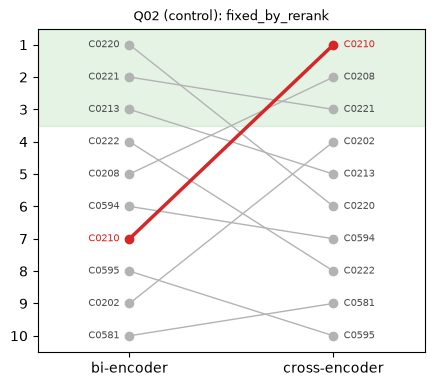


Pipeline 1 (baseline), top 3 sent to the LLM:
  [S1] C0220 (5.6.1): 5.6.1. During the draw phase, the following steps occur in order: a. The Corp gains their allotted clicks (default click click click). b. A  ...
  [S2] C0221 (5.6.2): 5.6.2. During the Corp’s action phase, the following steps occur in order: a. A paid ability window occurs, in which players may use paid ab ...
  [S3] C0213 (5.4.1-5.4.2): 5.4.1. The action phase is the first phase of the Runner’s turn and the second phase of the Corp’s turn. It is the only timing structure in  ...
Answer 1:
    The provided passages do not cover this.
  -> label: refused | citations: n/a

Pipeline 2 (re-ranked), top 3 sent to the LLM:
  [S1] C0210 (5.2.6)  GOLD: 5.2.6. Corp Actions a. The following BASIC ACTIONS are always available to the Corp during their action phase, in addition to any actions pr ...
  [S2] C0208 (5.2.3-5.2.4): 5.2.3. Each player has several basic actions they can always perform. The Corp’s basic actions are listed

In [33]:
evidence_pack("Q02")

### 9.2 Q29 (keyword trap): fixed by re-ranking

Q29 (keyword_trap): How does the Corp flip an installed card face up so that it starts working?
Result: fixed_by_rerank | stage: ranking
Expected answer:
    By rezzing it: the Corp pays the card's rez cost and turns it faceup. Assets and upgrades can be rezzed in
    paid ability windows, ice in the run's paid ability window at step 6.9.2b, and any card when a card
    ability allows it. Agendas cannot be rezzed.


,chunk_id,gold,section,bi_rank,bi_score,ce_rank,ce_score,shift,text
0,C0353,,8.5 Installing and Uninstalling Cards,1,0.551,2,3.30,-1,"8.5.15. Some abilities instruct the Corp to “install and rez” a card. To resolve this instruction, the Corp fi"
1,C0054,,"1.13 Host, Hosted, and Hosting",2,0.540,9,-3.20,-7,"1.13.7. Cards can be hosted faceup or facedown. a. Unless otherwise specified, a card that is hosted while it"
2,C0323,,8.1 Faceup and Facedown Status,3,0.521,7,0.21,-4,d. A Runner card turned facedown is not considered to be uninstalled and simply remains in the play area. e. I
3,C0320,GOLD,8.1 Faceup and Facedown Status,4,0.504,1,4.35,3,"e. To resolve rezzing a card, the Corp pays its rez cost (accounting for any modifiers or additional costs), a"
4,C0354,,8.5 Installing and Uninstalling Cards,5,0.503,6,0.41,-1,8.5.16. Steps of Installing a Card a. Place the card into the play area with the same faceup or facedown statu
5,C0348,,8.5 Installing and Uninstalling Cards,6,0.500,8,-0.21,-2,"8.5.13. If a player attempts to install a facedown card or a card from a hidden or secret zone, they are requi"
6,C0339,,8.5 Installing and Uninstalling Cards,7,0.492,5,1.06,2,8.5.3. Cards in servers cannot be rearranged unless instructed by a card ability. To organize this hidden info
7,C0370,,8.8 Swapping Cards,8,0.492,10,-4.60,-2,"b. If only one of the cards to be swapped is installed, then it becomes uninstalled as it moves to the destina"
8,C0338,,8.5 Installing and Uninstalling Cards,9,0.491,3,2.16,6,"8.5.2. Corp cards are installed facedown, unrezzed, and remain inactive until rezzed. Corp cards are installed"
9,C0017,,1.6 Starting the Game,10,0.489,4,1.06,6,1.6.1. The players decide who will play as the Corp and who will play as the Runner. Each player places an app


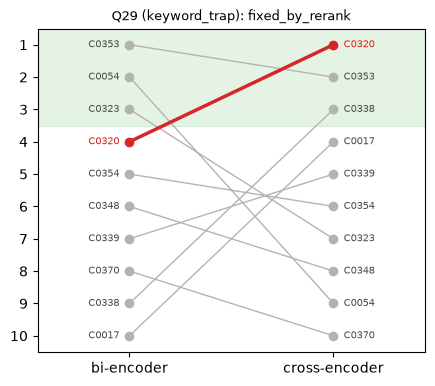


Pipeline 1 (baseline), top 3 sent to the LLM:
  [S1] C0353 (8.5.15): 8.5.15. Some abilities instruct the Corp to “install and rez” a card. To resolve this instruction, the Corp first installs the card normally ...
  [S2] C0054 (1.13.7-1.13.8): 1.13.7. Cards can be hosted faceup or facedown. a. Unless otherwise specified, a card that is hosted while it is being installed is hosted o ...
  [S3] C0323 (8.1.4): d. A Runner card turned facedown is not considered to be uninstalled and simply remains in the play area. e. If an installed facedown Runner ...
Answer 1:
    The provided passages do not cover this.
  -> label: refused | citations: n/a

Pipeline 2 (re-ranked), top 3 sent to the LLM:
  [S1] C0320 (8.1.2)  GOLD: e. To resolve rezzing a card, the Corp pays its rez cost (accounting for any modifiers or additional costs), a checkpoint occurs (as require ...
  [S2] C0353 (8.5.15): 8.5.15. Some abilities instruct the Corp to “install and rez” a card. To resolve this instruction, the Corp

In [34]:
evidence_pack("Q29")

### 9.3 Q35 (buried): fixed by re-ranking

Q35 (buried): In what order are cards from the Corp's deck offered to the Runner when R&D is breached?
Result: fixed_by_rerank | stage: ranking
Expected answer:
    From the top of the deck down, one card at a time, until the access limit is reached. If the deck changes
    during the breach, the topmost eligible card becomes the next candidate.


,chunk_id,gold,section,bi_rank,bi_score,ce_rank,ce_score,shift,text
0,C0168,,4.2 Deck,1,0.687,8,2.98,-7,4.2.4. The number of cards in a deck is open information. Any player may count the number of cards in a deck a
1,C0317,,7.5 Steps of Breaching a Server,2,0.671,4,5.31,-2,7.5.1. Breaching the server formally begins. Conditions related to breaching this server are met. 7.5.2. If th
2,C0044,,1.12 Objects,3,0.668,6,3.74,-3,"Example: The top card of R&D in the current game state is an object. So is the 2nd card from the top of R&D, t"
3,C0313,GOLD,7.4 Determining Candidates,4,0.667,1,7.03,3,"7.4.7. During a breach of R&D, the Runner is presented with 1 candidate from the Corp’s deck at a time in turn"
4,C0332,,8.3 Arranging and Rearranging Cards,5,0.665,9,2.80,-4,"Example: The Corp plays Cultivate, acting on the top 5 cards of R&D by trashing 1 card, adding 1 card to HQ, a"
5,C0316,,7.4 Determining Candidates,6,0.659,3,5.51,3,"b. One card, Showing Off, allows the Runner to access cards from the bottom of R&D. While this effect applies,"
6,C0600,,11.5 Timing Structure of Breaching a Server (Section 7.5),7,0.644,5,4.28,2,"1) The breach begins. 2) If breaching Archives, facedown cards in Archives are turned faceup. 3) If breaching"
7,C0200,,4.8 Set Aside,8,0.643,10,2.69,-2,4.8.7. Facedown cards in the set-aside zone must be kept in distinct groups according to the effect that sets
8,C0315,,7.4 Determining Candidates,9,0.639,2,5.95,7,Example: The Corp is playing Seidr Laboratories and has Strongbox rezzed in the root of R&D. The Runner breach
9,C0302,,7.4 Determining Candidates,10,0.636,7,3.34,3,7.4.1. The candidates at the beginning of a breach are as follows: a. Each card in the root of the breached se


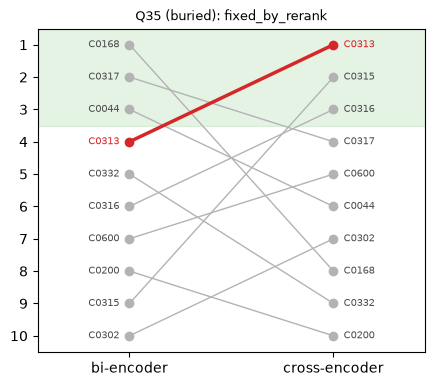


Pipeline 1 (baseline), top 3 sent to the LLM:
  [S1] C0168 (4.2.4-4.2.7): 4.2.4. The number of cards in a deck is open information. Any player may count the number of cards in a deck at any time. 4.2.5. Cards in a  ...
  [S2] C0317 (7.5.1-7.5.7): 7.5.1. Breaching the server formally begins. Conditions related to breaching this server are met. 7.5.2. If the breached server is Archives, ...
  [S3] C0044 (1.12.3): Example: The top card of R&D in the current game state is an object. So is the 2nd card from the top of R&D, the 3rd card, and so on. If the ...
Answer 1:
    The provided passages do not cover this.
  -> label: refused | citations: n/a

Pipeline 2 (re-ranked), top 3 sent to the LLM:
  [S1] C0313 (7.4.7)  GOLD: 7.4.7. During a breach of R&D, the Runner is presented with 1 candidate from the Corp’s deck at a time in turn, working down from the top of ...
  [S2] C0315 (7.4.7): Example: The Corp is playing Seidr Laboratories and has Strongbox rezzed in the root of R&D. The Runner 

In [35]:
evidence_pack("Q35")

### 9.4 Q41 (buried): fixed by re-ranking

Q41 (buried): If stealing an agenda would cause a breach of the same server during an ongoing breach, when does the second breach happen?
Result: fixed_by_rerank | stage: ranking
Expected answer:
    After the current breach ends: the new breach is delayed and takes place once the current breach is
    finished.


,chunk_id,gold,section,bi_rank,bi_score,ce_rank,ce_score,shift,text
0,C0138,,3.2 Agendas,1,0.508,7,-3.10,-6,"Agendas represent valuable pieces of Corporate data. When the Corp advances and scores agendas, it represents"
1,C0098,,"1.17 Score, Scoring and Stealing",2,0.497,6,-2.72,-4,e. If an effect directly adds an agenda to a score area or otherwise moves an agenda from any zone to a score
2,C0099,,"1.17 Score, Scoring and Stealing",3,0.496,5,-2.69,-2,"1.17.4. Agendas are always added to the score area faceup, regardless of their previous faceup/facedown status"
3,C0301,GOLD,7.3 Breaching Servers,4,0.487,1,2.37,3,7.3.7. An “end the run” effect that resolves while a server is being breached can sometimes end that breach. S
4,C0290,,7.1 Accessing Cards,5,0.449,2,0.69,3,"7.1.6. If, after resolving mid-access abilities, the Runner is still accessing an agenda, they must steal it."
5,C0100,,"1.17 Score, Scoring and Stealing",6,0.437,3,-1.57,3,"1.17.8. If an ability meets its trigger condition from an agenda being scored or stolen, the agenda’s last kno"
6,C0097,,"1.17 Score, Scoring and Stealing",7,0.436,9,-5.13,-2,1.17.3. Players add agendas to their score areas by SCORING or STEALING them. The Corp can score an agenda to
7,C0600,,11.5 Timing Structure of Breaching a Server (Section 7.5),8,0.429,8,-3.50,0,"1) The breach begins. 2) If breaching Archives, facedown cards in Archives are turned faceup. 3) If breaching"
8,C0328,,8.2 Card Movements,9,0.427,10,-6.99,-1,"8.2.7. To PLAY an event or operation is to move it from its current zone to the play area, resolve its play ab"
9,C0311,,7.4 Determining Candidates,10,0.402,4,-2.27,6,7.4.6. Cards entering a server while a breach is in progress can become candidates. a. If a card enters the ro


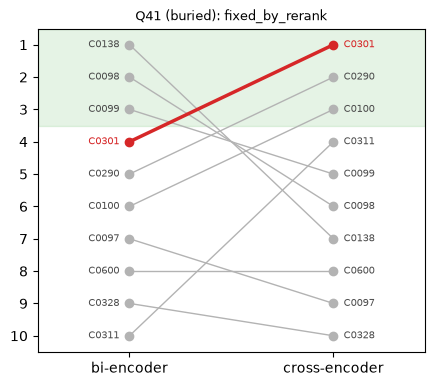


Pipeline 1 (baseline), top 3 sent to the LLM:
  [S1] C0138 (3.2.1-3.2.2): Agendas represent valuable pieces of Corporate data. When the Corp advances and scores agendas, it represents completion of critical Corpora ...
  [S2] C0098 (1.17.3): e. If an effect directly adds an agenda to a score area or otherwise moves an agenda from any zone to a score area, that agenda is not consi ...
  [S3] C0099 (1.17.4-1.17.7): 1.17.4. Agendas are always added to the score area faceup, regardless of their previous faceup/facedown status. 1.17.5. If an installed agen ...
Answer 1:
    The provided passages do not cover this.
  -> label: refused | citations: n/a

Pipeline 2 (re-ranked), top 3 sent to the LLM:
  [S1] C0301 (7.3.7-7.3.8)  GOLD: 7.3.7. An “end the run” effect that resolves while a server is being breached can sometimes end that breach. See section 6.1.4. 7.3.8. If a  ...
  [S2] C0290 (7.1.6-7.1.8): 7.1.6. If, after resolving mid-access abilities, the Runner is still accessing an agenda, 

In [36]:
evidence_pack("Q41")

### 9.5 Q23 (negation): hurt by re-ranking

Q23 (negation): Can the Runner have two consoles installed at the same time?
Result: hurt_by_rerank | stage: ranking
Expected answer:
    No. Consoles are 'Limit 1 console per player': if the Runner ever controls more than one installed
    console, all but the most recently active one are trashed, and this cannot be prevented. Having several
    consoles in the deck is allowed.


,chunk_id,gold,section,bi_rank,bi_score,ce_rank,ce_score,shift,text
0,C0153,GOLD,3.8 Hardware,1,0.465,7,-3.32,-6,3.8.5. Consoles a. Some hardware have the subtype console. All consoles have the text “Limit 1 console per pla
1,C0340,,8.5 Installing and Uninstalling Cards,2,0.413,2,0.10,0,"8.5.5. Installing cards is an exception to rule 9.12.2a. If an effect would install more than one card, then t"
2,C0069,,1.15 Targets,3,0.380,1,2.18,2,Example: The Runner accesses an Aggressive Secretary with three advancement counters on it. The Runner only ha
3,C0152,,3.8 Hardware,4,0.373,3,-1.74,1,"The Runner’s hardware are the physical tools at their disposal: the computers, chips, and other machinery that"
4,C0322,,8.1 Faceup and Facedown Status,5,0.364,8,-4.07,-3,8.1.4. Some abilities can install Runner cards facedown or turn already-installed Runner cards facedown. a. In
5,C0339,,8.5 Installing and Uninstalling Cards,6,0.364,6,-3.19,0,8.5.3. Cards in servers cannot be rearranged unless instructed by a card ability. To organize this hidden info
6,C0053,,"1.13 Host, Hosted, and Hosting",7,0.353,5,-2.72,2,"Example: Egret states, “Install only on a rezzed piece of ice.” The Runner can only install Egret if there is"
7,C0552,GOLD,10.3 Checkpoints,8,0.344,4,-1.82,4,Example: The Corp has Targeted Marketing in the play area when the Runner steals an agenda. In the next checkp
8,C0540,,9.12 Other Rules and Terminology,9,0.343,10,-10.70,-1,d. A persisting ability is only applicable to the run during which it began to persist. After the checkpoint f
9,C0575,,10.10 Charge,10,0.336,9,-9.06,1,"A Runner’s life is one of fluidity and adaptation; their rig is in a constant state of repair of upgrade, hide"


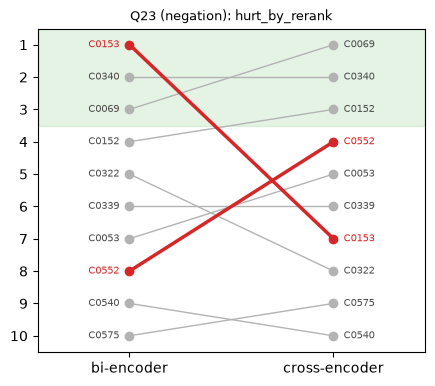


Pipeline 1 (baseline), top 3 sent to the LLM:
  [S1] C0153 (3.8.5)  GOLD: 3.8.5. Consoles a. Some hardware have the subtype console. All consoles have the text “Limit 1 console per player.” b. If a player ever cont ...
  [S2] C0340 (8.5.5): 8.5.5. Installing cards is an exception to rule 9.12.2a. If an effect would install more than one card, then those cards are chosen and inst ...
  [S3] C0069 (1.15.2): Example: The Runner accesses an Aggressive Secretary with three advancement counters on it. The Runner only has two installed programs, so t ...
Answer 1:
    No. If a player ever controls more than one installed console, all but the most recently active console
    are trashed [S1b]. All consoles have the text "Limit 1 console per player," and this limitation applies to
    active consoles [S1a, S1d]. Trashing cards this way cannot be prevented [S1b].
  -> label: correct | citations: ok

Pipeline 2 (re-ranked), top 3 sent to the LLM:
  [S1] C0069 (1.15.2): Example: The Runner access

In [37]:
evidence_pack("Q23")

### 9.6 Q32 (keyword trap): hurt by re-ranking

Q32 (keyword_trap): What happens when the Corp runs out of cards in their deck and has to draw?
Result: hurt_by_rerank | stage: ranking
Expected answer:
    The Runner wins the game: if the Corp must draw from R&D while it is empty, the Runner wins.


,chunk_id,gold,section,bi_rank,bi_score,ce_rank,ce_score,shift,text
0,C0222,,5.6 Steps of the Corp’s Turn,1,0.552,6,1.41,-5,"5.6.3. During the Corp’s discard phase, the following steps occur in order: a. The Corp discards cards to reac"
1,C0200,,4.8 Set Aside,2,0.551,3,2.77,-1,4.8.7. Facedown cards in the set-aside zone must be kept in distinct groups according to the effect that sets
2,C0168,GOLD,4.2 Deck,3,0.548,4,2.38,-1,4.2.4. The number of cards in a deck is open information. Any player may count the number of cards in a deck a
3,C0220,,5.6 Steps of the Corp’s Turn,4,0.538,5,1.56,-1,"5.6.1. During the draw phase, the following steps occur in order: a. The Corp gains their allotted clicks (def"
4,C0582,,10.12 Sabotage,5,0.520,8,0.11,-3,"10.12.3. In resolving a “sabotage N” effect, the Corp may be required to trash cards from a certain zone if th"
5,C0024,,1.8 Cards,6,0.510,10,-2.39,-4,1.8.4. Cards that are INACTIVE are unable to affect the game or have most of their abilities used. a. Cards ar
6,C0221,,5.6 Steps of the Corp’s Turn,7,0.508,9,-1.08,-2,"5.6.2. During the Corp’s action phase, the following steps occur in order: a. A paid ability window occurs, in"
7,C0311,,7.4 Determining Candidates,8,0.508,7,0.44,1,7.4.6. Cards entering a server while a breach is in progress can become candidates. a. If a card enters the ro
8,C0313,,7.4 Determining Candidates,9,0.505,2,3.50,7,"7.4.7. During a breach of R&D, the Runner is presented with 1 candidate from the Corp’s deck at a time in turn"
9,C0335,,8.4 Drawing Cards,10,0.504,1,4.66,9,Example: The Corp takes their mandatory draw while they have Daily Business Show and Raman Rai rezzed. They se


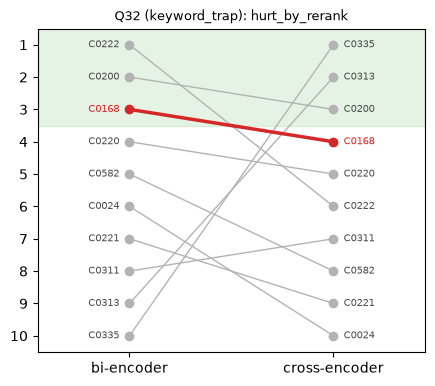


Pipeline 1 (baseline), top 3 sent to the LLM:
  [S1] C0222 (5.6.3): 5.6.3. During the Corp’s discard phase, the following steps occur in order: a. The Corp discards cards to reach their maximum hand size. b.  ...
  [S2] C0200 (4.8.7): 4.8.7. Facedown cards in the set-aside zone must be kept in distinct groups according to the effect that sets them aside. Cards within such  ...
  [S3] C0168 (4.2.4-4.2.7)  GOLD: 4.2.4. The number of cards in a deck is open information. Any player may count the number of cards in a deck at any time. 4.2.5. Cards in a  ...
Answer 1:
    If the Corp must ever draw from R&D while it is empty, the Runner wins the game [S3].
  -> label: correct | citations: ok

Pipeline 2 (re-ranked), top 3 sent to the LLM:
  [S1] C0335 (8.4.3): Example: The Corp takes their mandatory draw while they have Daily Business Show and Raman Rai rezzed. They set aside Wraparound and Enigma  ...
  [S2] C0313 (7.4.7): 7.4.7. During a breach of R&D, the Runner is presented with 1 candi

In [38]:
evidence_pack("Q32")

### 9.7 Q36 (buried): hurt by re-ranking

Q36 (buried): What does the Runner do in a breach when there are no more cards left to choose from?
Result: hurt_by_rerank | stage: ranking
Expected answer:
    They skip to the end of the breach: if the Runner cannot choose a candidate, the breach is complete.


,chunk_id,gold,section,bi_rank,bi_score,ce_rank,ce_score,shift,text
0,C0317,GOLD,7.5 Steps of Breaching a Server,1,0.669,9,4.09,-8,7.5.1. Breaching the server formally begins. Conditions related to breaching this server are met. 7.5.2. If th
1,C0313,,7.4 Determining Candidates,2,0.669,3,6.26,-1,"7.4.7. During a breach of R&D, the Runner is presented with 1 candidate from the Corp’s deck at a time in turn"
2,C0307,,7.4 Determining Candidates,3,0.660,10,3.85,-7,"Example: The Runner breaches HQ during a run on HQ while Flagship is rezzed in the root of HQ, and they have a"
3,C0295,,7.3 Breaching Servers,4,0.656,1,6.82,3,"7.3.4. During a breach, the Runner is presented with the current candidates. They choose 1 of those cards and"
4,C0297,,7.3 Breaching Servers,5,0.650,4,5.95,1,7.3.5. The Runner can only choose candidates from the Corp’s hand or deck a limited number of times during a b
5,C0308,,7.4 Determining Candidates,6,0.650,2,6.61,4,"7.4.3. Once the Runner chooses a candidate for access, it ceases to be a candidate for the remainder of that b"
6,C0556,,10.3 Checkpoints,7,0.647,6,5.27,1,j. If a server is being breached and 1 or more cards entered the root of that server since the previous checkp
7,C0310,,7.4 Determining Candidates,8,0.642,7,5.26,1,"7.4.4. When the random access limit is reached during a breach of HQ or R&D, all candidates in the zone corres"
8,C0306,,7.4 Determining Candidates,9,0.632,8,5.00,1,b. Some abilities state that the Runner “cannot access more than 1 card” during a particular run. The effect o
9,C0291,,7.1 Accessing Cards,10,0.624,5,5.39,5,"7.1.9. One card, Information Sifting, uses a method other than a breach to establish a set of cards for the Ru"


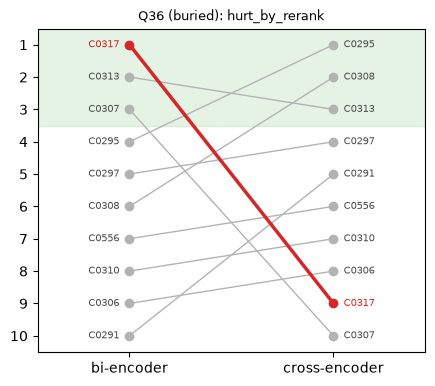


Pipeline 1 (baseline), top 3 sent to the LLM:
  [S1] C0317 (7.5.1-7.5.7)  GOLD: 7.5.1. Breaching the server formally begins. Conditions related to breaching this server are met. 7.5.2. If the breached server is Archives, ...
  [S2] C0313 (7.4.7): 7.4.7. During a breach of R&D, the Runner is presented with 1 candidate from the Corp’s deck at a time in turn, working down from the top of ...
  [S3] C0307 (7.4.2): Example: The Runner breaches HQ during a run on HQ while Flagship is rezzed in the root of HQ, and they have an installed copy of Docklands  ...
Answer 1:
    If the Runner cannot choose a candidate, they skip to step 7.5.7 [S1]. At step 7.5.7, the breach is
    complete and conditions related to the breach ending are met [S1].
  -> label: correct | citations: ok

Pipeline 2 (re-ranked), top 3 sent to the LLM:
  [S1] C0295 (7.3.4): 7.3.4. During a breach, the Runner is presented with the current candidates. They choose 1 of those cards and access it. This process repeat ...
  [S

In [39]:
evidence_pack("Q36")

### 9.8 Q18 (negation): both pipelines fail

Q18 (negation): If one effect says a player must do something and another effect says they cannot, which one applies?
Result: both_fail | stage: ranking
Expected answer:
    The 'cannot' effect wins: if a rule or ability says something happens but another effect says it cannot
    happen, it does not happen.


,chunk_id,gold,section,bi_rank,bi_score,ce_rank,ce_score,shift,text
0,C0521,,9.12 Other Rules and Terminology,1,0.489,4,2.08,-3,c. If more than one effect gives a player a choice of how to resolve an ability or game rule such that both pl
1,C0085,,1.16 Costs,2,0.467,5,1.77,-3,"b. The presence of an install cost, rez cost, or play cost does not change the optional or mandatory status of"
2,C0208,,5.2 Actions,3,0.450,7,-0.18,-4,5.2.3. Each player has several basic actions they can always perform. The Corp’s basic actions are listed in s
3,C0534,,9.12 Other Rules and Terminology,4,0.448,3,2.53,1,9.12.3. Must a. If a card ability states that a player “must” do something without stipulating how that player
4,C0535,,9.12 Other Rules and Terminology,5,0.437,2,2.88,3,Example: The Runner has Imp and Neutralize All Threats installed when they access a card with a trash cost gre
5,C0002,GOLD,1.2 Golden Rules,6,0.432,6,0.37,0,"1.2.1. If the text of a card directly contradicts these rules, the text of the card takes precedence. 1.2.2. I"
6,C0063,,1.14 Ownership and Control,7,0.431,8,-0.62,-1,"1.14.5. Unless otherwise noted, the controller of an ability carries out its effects and makes any choices req"
7,C0209,,5.2 Actions,8,0.430,10,-5.83,-2,5.2.5. Some cards refer to players taking “the same action” or “different actions”. a. Actions a player perfor
8,C0381,,9.1 General,9,0.425,9,-3.19,0,"9.1.5. Whereas an ability, instruction, or declaration is made up of text, an EFFECT is what happens in the ga"
9,C0500,,9.9 Interrupts and Replacement Effects,10,0.422,1,3.63,9,"9.9.11. If multiple replacement effects would apply to an effect acting on a targeted card, that card’s contro"


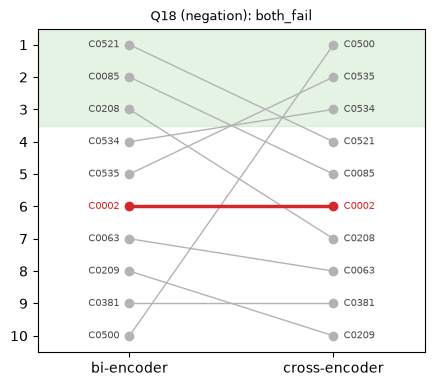


Pipeline 1 (baseline), top 3 sent to the LLM:
  [S1] C0521 (9.12.1): c. If more than one effect gives a player a choice of how to resolve an ability or game rule such that both players are instructed to make a ...
  [S2] C0085 (1.16.4): b. The presence of an install cost, rez cost, or play cost does not change the optional or mandatory status of an ability. If an effect dire ...
  [S3] C0208 (5.2.3-5.2.4): 5.2.3. Each player has several basic actions they can always perform. The Corp’s basic actions are listed in section 5.2.6, and the Runner’s ...
Answer 1:
    The provided passages do not cover this.
  -> label: refused | citations: n/a

Pipeline 2 (re-ranked), top 3 sent to the LLM:
  [S1] C0500 (9.9.11): 9.9.11. If multiple replacement effects would apply to an effect acting on a targeted card, that card’s controller chooses the order in whic ...
  [S2] C0535 (9.12.3): Example: The Runner has Imp and Neutralize All Threats installed when they access a card with a trash cost greate

In [40]:
evidence_pack("Q18")

### 9.9 Q34 (buried): both pipelines fail

Q34 (buried): While the Runner is breaching HQ, a new card enters the Corp's hand. Can the Runner access it?
Result: both_fail | stage: ranking
Expected answer:
    Yes, as long as the random access limit has not been reached yet: the new card becomes a candidate the
    Runner can access.


,chunk_id,gold,section,bi_rank,bi_score,ce_rank,ce_score,shift,text
0,C0307,,7.4 Determining Candidates,1,0.680,1,7.54,0,"Example: The Runner breaches HQ during a run on HQ while Flagship is rezzed in the root of HQ, and they have a"
1,C0293,,7.3 Breaching Servers,2,0.626,8,5.70,-6,7.3.1. BREACHING a server is the process of the Runner accessing a particular set of cards associated with tha
2,C0305,,7.4 Determining Candidates,3,0.621,7,5.75,-4,Example: The Runner breaches HQ during a run on HQ while Flagship is rezzed in the root of HQ. They have an in
3,C0311,GOLD,7.4 Determining Candidates,4,0.615,5,6.64,-1,7.4.6. Cards entering a server while a breach is in progress can become candidates. a. If a card enters the ro
4,C0297,,7.3 Breaching Servers,5,0.614,4,6.99,1,7.3.5. The Runner can only choose candidates from the Corp’s hand or deck a limited number of times during a b
5,C0286,,7.1 Accessing Cards,6,0.609,9,5.59,-3,7.1.1. ACCESSING is the process of the Corp showing one of their cards to the Runner for potential interaction
6,C0295,,7.3 Breaching Servers,7,0.597,3,7.27,4,"7.3.4. During a breach, the Runner is presented with the current candidates. They choose 1 of those cards and"
7,C0310,,7.4 Determining Candidates,8,0.596,6,5.80,2,"7.4.4. When the random access limit is reached during a breach of HQ or R&D, all candidates in the zone corres"
8,C0296,,7.3 Breaching Servers,9,0.595,2,7.38,7,"b. One card, Dedicated Neural Net, instructs the Corp to choose which cards the Runner accesses from HQ. While"
9,C0172,,4.3 Hand,10,0.583,10,2.64,0,"4.3.8. HQ HQ stands for Headquarters. It represents the projects, staff, technology, and other assets the Corp"


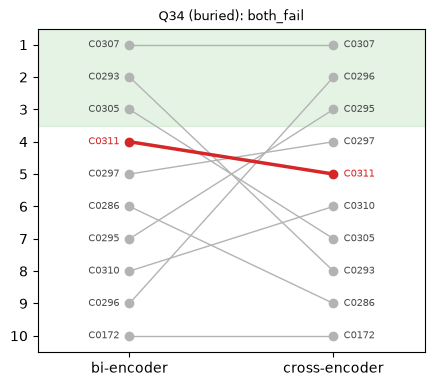


Pipeline 1 (baseline), top 3 sent to the LLM:
  [S1] C0307 (7.4.2): Example: The Runner breaches HQ during a run on HQ while Flagship is rezzed in the root of HQ, and they have an installed copy of Docklands  ...
  [S2] C0293 (7.3.1): 7.3.1. BREACHING a server is the process of the Runner accessing a particular set of cards associated with that server. Most accesses occur  ...
  [S3] C0305 (7.4.2): Example: The Runner breaches HQ during a run on HQ while Flagship is rezzed in the root of HQ. They have an installed copy of Docklands Pass ...
Answer 1:
    Yes, the Runner can access a new card that enters the Corp's hand during a breach, provided it becomes a
    candidate. After the Runner accesses a card during a breach, that object remains visible to the Runner for
    the remainder of the breach [S2]. If a card is installed from HQ during a breach, the Runner will know
    whether the Corp installs a previously accessed card or an unknown card from the rest of HQ [S2]. If a
    rest

In [41]:
evidence_pack("Q34")

### 9.10 Q12 (exception): recall ceiling

Q12 (exception): What happens to cards hosted on a card that moves from the Corp's score area to the Runner's score area?
Result: recall_ceiling | stage: retrieval_recall
Expected answer:
    They are not trashed. Hosted objects are normally trashed when their host changes zones, but moving from
    one player's score area to the other player's score area is the exception.


,chunk_id,gold,section,bi_rank,bi_score,ce_rank,ce_score,shift,text
0,C0200,,4.8 Set Aside,1,0.576,8,0.04,-7,4.8.7. Facedown cards in the set-aside zone must be kept in distinct groups according to the effect that sets
1,C0182,,4.6 Play Area,2,0.573,5,1.03,-3,"e. Credits in the play area are always placed in a designated location: the Corp’s credit pool, the Runner’s c"
2,C0180,,4.6 Play Area,3,0.572,7,0.25,-4,4.6.4. Whether or not a card is active while in the play area is determined by the card’s status. a. Identitie
3,C0023,,1.8 Cards,4,0.568,3,2.74,1,1.8.3. Cards that are ACTIVE are able to affect the game through their abilities. a. Runner cards that are ins
4,C0048,,"1.13 Host, Hosted, and Hosting",5,0.560,2,3.92,3,"1.13.1. Whenever an object is “placed” or “loaded” onto a card, a host relationship is created between those t"
5,C0332,,8.3 Arranging and Rearranging Cards,6,0.557,10,-0.76,-4,"Example: The Corp plays Cultivate, acting on the top 5 cards of R&D by trashing 1 card, adding 1 card to HQ, a"
6,C0024,,1.8 Cards,7,0.553,9,-0.07,-2,1.8.4. Cards that are INACTIVE are unable to affect the game or have most of their abilities used. a. Cards ar
7,C0328,,8.2 Card Movements,8,0.553,1,5.11,7,"8.2.7. To PLAY an event or operation is to move it from its current zone to the play area, resolve its play ab"
8,C0310,,7.4 Determining Candidates,9,0.552,6,0.91,3,"7.4.4. When the random access limit is reached during a breach of HQ or R&D, all candidates in the zone corres"
9,C0021,,1.7 Ending the Game,10,0.549,4,1.55,6,1.7.2. Each player has two possible win conditions available. a. Either player can win by collecting agenda po


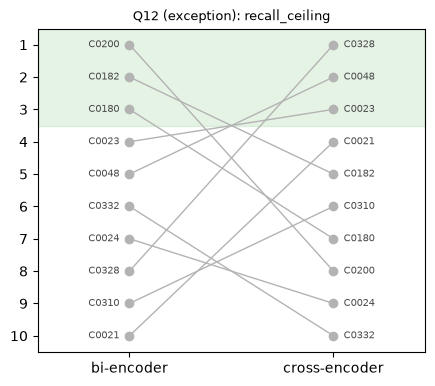


Pipeline 1 (baseline), top 3 sent to the LLM:
  [S1] C0200 (4.8.7): 4.8.7. Facedown cards in the set-aside zone must be kept in distinct groups according to the effect that sets them aside. Cards within such  ...
  [S2] C0182 (4.6.5): e. Credits in the play area are always placed in a designated location: the Corp’s credit pool, the Runner’s credit pool, the bad publicity  ...
  [S3] C0180 (4.6.4): 4.6.4. Whether or not a card is active while in the play area is determined by the card’s status. a. Identities start the game in the play a ...
Answer 1:
    The provided passages do not cover this.
  -> label: refused | citations: n/a

Pipeline 2 (re-ranked), top 3 sent to the LLM:
  [S1] C0328 (8.2.7-8.2.10): 8.2.7. To PLAY an event or operation is to move it from its current zone to the play area, resolve its play abilities, and then trash it. Th ...
  [S2] C0048 (1.13.1-1.13.2): 1.13.1. Whenever an object is “placed” or “loaded” onto a card, a host relationship is created between those

In [42]:
evidence_pack("Q12")

### 9.11 Q42 (keyword trap): recall ceiling

Q42 (keyword_trap): What happens if I have two copies of a card with the diamond symbol in play?
Result: recall_ceiling | stage: retrieval_recall
Expected answer:
    Only one copy can be active at a time. When the newer copy becomes active, the other copy is trashed
    during the next checkpoint, and this cannot be prevented; the most recently active copy stays.


,chunk_id,gold,section,bi_rank,bi_score,ce_rank,ce_score,shift,text
0,C0015,,1.5 Extra Cards,1,0.406,6,-7.38,-5,"1.5.4. Two cards, Rebirth and DJ Fenris, make use of identity cards other than the one selected by the player"
1,C0112,,2.2 Unique Symbol,2,0.402,4,-6.06,-2,"2.2.1. Some cards are UNIQUE, and have a unique symbol (♦) before their name to designate this. See rule 10.1."
2,C0012,,1.5 Extra Cards,3,0.389,1,-3.62,2,b. A player playing Méliès U as their identity may bring any number of copies of that identity along with thei
3,C0545,,10.1 General,4,0.387,5,-7.21,-1,10.1.5. Some cards are written with self-referential language. If a card references its own name without using
4,C0368,,8.8 Swapping Cards,5,0.369,3,-5.24,2,"8.8.3. If two installed cards are swapped, each card moves to the other’s location simultaneously. The two car"
5,C0369,,8.8 Swapping Cards,6,0.364,2,-4.27,4,"8.8.4. If two cards are swapped between zones, each card moves to the zone the other is in simultaneously. a."
6,C0016,,1.5 Extra Cards,7,0.364,7,-8.07,0,"c. In a tournament, all identities brought to the game this way must be legal for players to use as their actu"
7,C0054,,"1.13 Host, Hosted, and Hosting",8,0.363,10,-10.99,-2,"1.13.7. Cards can be hosted faceup or facedown. a. Unless otherwise specified, a card that is hosted while it"
8,C0048,,"1.13 Host, Hosted, and Hosting",9,0.359,8,-8.95,1,"1.13.1. Whenever an object is “placed” or “loaded” onto a card, a host relationship is created between those t"
9,C0024,,1.8 Cards,10,0.359,9,-9.69,1,1.8.4. Cards that are INACTIVE are unable to affect the game or have most of their abilities used. a. Cards ar


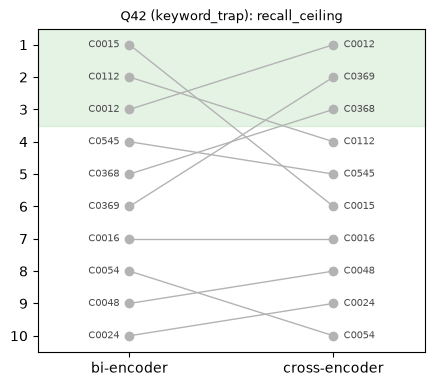


Pipeline 1 (baseline), top 3 sent to the LLM:
  [S1] C0015 (1.5.4): 1.5.4. Two cards, Rebirth and DJ Fenris, make use of identity cards other than the one selected by the player during deck construction. a. A ...
  [S2] C0112 (2.2.1): 2.2.1. Some cards are UNIQUE, and have a unique symbol (♦) before their name to designate this. See rule 10.1.1. ...
  [S3] C0012 (1.5.2): b. A player playing Méliès U as their identity may bring any number of copies of that identity along with their deck. At the start of the ga ...
Answer 1:
    The provided passages do not cover this.
  -> label: refused | citations: n/a

Pipeline 2 (re-ranked), top 3 sent to the LLM:
  [S1] C0012 (1.5.2): b. A player playing Méliès U as their identity may bring any number of copies of that identity along with their deck. At the start of the ga ...
  [S2] C0369 (8.8.4): 8.8.4. If two cards are swapped between zones, each card moves to the zone the other is in simultaneously. a. Each of the swapped cards ente ...
  [S3]

In [43]:
evidence_pack("Q42")

### 9.12 Summary of the diagnoses

In [44]:
diagnosis = pd.DataFrame([{"qid": qid, "category": results[qid]["category"], "result": result_of[qid],
                           "stage": labels[qid]["stage"], "Answer 1": labels[qid]["answer1"], "Answer 2": labels[qid]["answer2"]}
                          for qid in failure_ids]).sort_values(["result", "qid"])
print("Failing stage per query:", diagnosis["stage"].value_counts().to_dict())
diagnosis


Failing stage per query: {'ranking': 9, 'retrieval_recall': 2}


,qid,category,result,stage,Answer 1,Answer 2
2,Q18,negation,both_fail,ranking,refused,refused
6,Q34,buried,both_fail,ranking,hallucinated,hallucinated
0,Q02,control,fixed_by_rerank,ranking,refused,correct
4,Q29,keyword_trap,fixed_by_rerank,ranking,refused,correct
7,Q35,buried,fixed_by_rerank,ranking,refused,correct
9,Q41,buried,fixed_by_rerank,ranking,refused,correct
3,Q23,negation,hurt_by_rerank,ranking,correct,refused
5,Q32,keyword_trap,hurt_by_rerank,ranking,correct,refused
8,Q36,buried,hurt_by_rerank,ranking,correct,refused
1,Q12,exception,recall_ceiling,retrieval_recall,refused,refused


## 10. Latency and scaling (Stage 8)

**Method**
- All times use `time.perf_counter()`. The models were loaded in Section 1, so model loading is **not** in these numbers.
- Retrieval stages run on the device chosen in Section 1.3: 3 untimed warm-up passes, then **20 repeats over all 23 final queries**. Median, mean and 95th percentile (p95) are reported.
- `sentence-transformers` returns numpy arrays, which waits for the device to finish, so the timings include the full computation.
- The LLM is timed separately with **one real call per query and pipeline**, bypassing the cache. These times include the network and Google's servers, which vary much more than the local stages.

In [45]:
# Retrieval stages. The models are already loaded (load time is not counted). 3 untimed warm-up passes,
# then 20 timed passes over all 23 final queries, on the device chosen in Section 1.3.
for _ in range(CONFIG["latency_warmup"]):
    for q in final_queries:
        rerank(q["query"], retrieve(q["query"])[0])

runs = []
for repeat in range(CONFIG["latency_repeats"]):
    for q in final_queries:
        hits, t_retrieve = retrieve(q["query"])
        _, t_rerank = rerank(q["query"], hits)
        runs.append({"qid": q["qid"], "repeat": repeat, **t_retrieve, **t_rerank})

latency = pd.DataFrame(runs)
latency["retrieval_p1_ms"] = latency["encode_ms"] + latency["search_ms"]       # Pipeline 1: encode + search
latency["retrieval_p2_ms"] = latency["retrieval_p1_ms"] + latency["ce_ms"]     # Pipeline 2: the same + cross-encoder
latency.to_csv(ROOT / "artifacts/latency.csv", index=False)
print(len(latency), "timed runs on device", CONFIG["device"], "(raw runs in artifacts/latency.csv)")


460 timed runs on device mps (raw runs in artifacts/latency.csv)


In [46]:
# LLM time: one real Gemini call per query and pipeline, bypassing the cache (46 calls).
# The free tier allows few calls per day, so the timings are saved once and re-loaded on a re-run.
# To measure again, delete artifacts/llm_latency.csv and explicitly set allow_live_llm_calls to True.
LLM_LATENCY_PATH = ROOT / "artifacts/llm_latency.csv"
if LLM_LATENCY_PATH.exists():
    llm_latency = pd.read_csv(LLM_LATENCY_PATH)
    print("loaded the saved LLM timings from", LLM_LATENCY_PATH.name)
else:
    if not CONFIG["allow_live_llm_calls"]:
        raise RuntimeError("LLM timing is not cached. Set CONFIG['allow_live_llm_calls'] = True before measuring it.")
    rows = []
    for qid, r in results.items():
        for pipeline, key in [("P1 baseline", "baseline"), ("P2 re-rank", "reranked")]:
            _, seconds = call_gemini(r[key]["prompt"])          # only the successful attempt is timed
            rows.append({"qid": qid, "pipeline": pipeline, "llm_ms": seconds * 1000})
            time.sleep(4)                                        # stay under the free tier's requests-per-minute limit
    llm_latency = pd.DataFrame(rows)
    llm_latency.to_csv(LLM_LATENCY_PATH, index=False)
print(len(llm_latency), "LLM calls timed, model", CONFIG["llm_model"])


loaded the saved LLM timings from llm_latency.csv
46 LLM calls timed, model gemini-3.1-flash-lite


### 10.1 Latency table

Pipeline 1 and Pipeline 2 share the query encoding and the FAISS search; Pipeline 2 adds the cross-encoder on 10 pairs (one batch). End-to-end = the query's median retrieval time + its LLM call. The two LLM rows are different prompts sent at different moments, so their difference mostly reflects the API's variance; the cost that re-ranking itself adds is the cross-encoder row.

In [47]:
def stats(values):
    values = np.asarray(values, dtype=float)
    return {"median": np.median(values), "mean": values.mean(), "p95": np.percentile(values, 95)}

llm = llm_latency.pivot(index="qid", columns="pipeline", values="llm_ms")
per_query = latency.groupby("qid")[["retrieval_p1_ms", "retrieval_p2_ms"]].median()   # median retrieval time of each query
end_to_end_p1 = per_query["retrieval_p1_ms"] + llm["P1 baseline"]
end_to_end_p2 = per_query["retrieval_p2_ms"] + llm["P2 re-rank"]

stages = [  # (stage, Pipeline 1 values, Pipeline 2 values), all in ms
    ("query encoding (bi-encoder)", latency["encode_ms"], latency["encode_ms"]),
    ("FAISS search, top 10", latency["search_ms"], latency["search_ms"]),
    ("cross-encoder, 10 pairs", None, latency["ce_ms"]),
    ("retrieval subtotal", latency["retrieval_p1_ms"], latency["retrieval_p2_ms"]),
    ("LLM generation (Gemini)", llm["P1 baseline"], llm["P2 re-rank"]),
    ("end-to-end", end_to_end_p1, end_to_end_p2),
]
rows = []
for stage, p1, p2 in stages:
    row = {"stage": stage}
    for pipeline, values in [("P1", p1), ("P2", p2)]:
        if values is not None:
            row.update({f"{pipeline} {name}": value for name, value in stats(values).items()})
    rows.append(row)
latency_table = pd.DataFrame(rows).set_index("stage").round(2)

ce_ms = latency["ce_ms"].median()
print(f"Re-rank overhead (median): {ce_ms:.1f} ms = {100 * ce_ms / latency['retrieval_p2_ms'].median():.0f}% of Pipeline 2 retrieval, "
      f"{100 * ce_ms / end_to_end_p2.median():.1f}% of Pipeline 2 end-to-end")
print(f"Share of end-to-end time spent in the LLM (median): P1 {100 * llm['P1 baseline'].median() / end_to_end_p1.median():.1f}%, "
      f"P2 {100 * llm['P2 re-rank'].median() / end_to_end_p2.median():.1f}%")
print("Retrieval rows: 20 repeats x 23 queries. LLM and end-to-end rows: 1 call per query (network and API time included).")
latency_table.fillna("-")


Re-rank overhead (median): 35.2 ms = 88% of Pipeline 2 retrieval, 2.0% of Pipeline 2 end-to-end
Share of end-to-end time spent in the LLM (median): P1 99.7%, P2 97.9%
Retrieval rows: 20 repeats x 23 queries. LLM and end-to-end rows: 1 call per query (network and API time included).


,P1 median,P1 mean,P1 p95,P2 median,P2 mean,P2 p95
stage,,,,,,
query encoding (bi-encoder),4.76,4.9,5.81,4.76,4.90,5.81
"FAISS search, top 10",0.03,0.04,0.04,0.03,0.04,0.04
"cross-encoder, 10 pairs",-,-,-,35.20,35.32,38.20
retrieval subtotal,4.8,4.93,5.84,39.94,40.25,43.55
LLM generation (Gemini),1322.52,5036.43,7439.18,1764.57,5418.75,14826.25
end-to-end,1327.16,5041.26,7444.06,1803.16,5458.35,14865.88


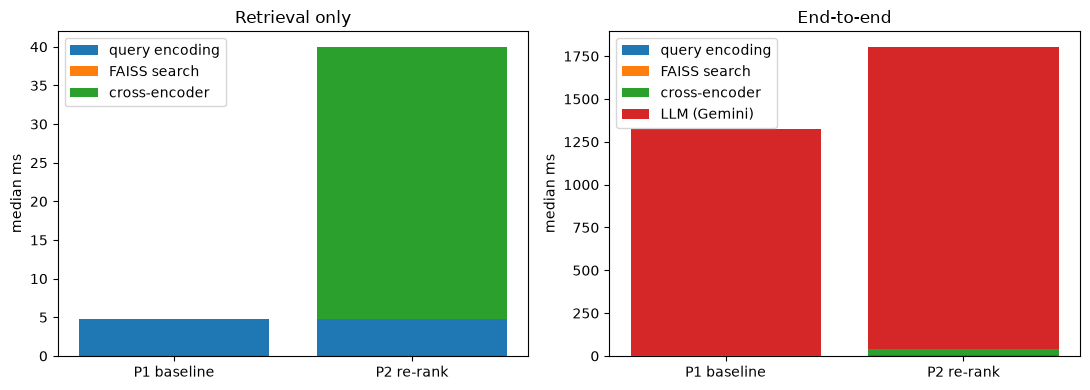

In [48]:
pipelines = ["P1 baseline", "P2 re-rank"]
parts = {"query encoding": [latency["encode_ms"].median()] * 2,
         "FAISS search": [latency["search_ms"].median()] * 2,
         "cross-encoder": [0, ce_ms]}

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
bottom = np.zeros(2)
for name, values in parts.items():
    left.bar(pipelines, values, bottom=bottom, label=name)
    bottom += values
left.set_title("Retrieval only"); left.set_ylabel("median ms"); left.legend()

parts["LLM (Gemini)"] = [llm["P1 baseline"].median(), llm["P2 re-rank"].median()]
bottom = np.zeros(2)
for name, values in parts.items():
    right.bar(pipelines, values, bottom=bottom, label=name)
    bottom += values
right.set_title("End-to-end"); right.set_ylabel("median ms"); right.legend()
fig.tight_layout()
fig.savefig(ROOT / "artifacts/figures/latency_bars.png", dpi=110)
plt.show()


### 10.2 Scaling: why not run the cross-encoder over the whole corpus?

The cross-encoder needs one forward pass **per (query, chunk) pair** at query time; nothing can be computed in advance, because it reads the query and the chunk together. The bi-encoder embeds all chunks once, offline, so each query costs one encoding plus a vector search.

Three measurements:
1. **Cross-encoder time against the number of candidates** n = 10, 25, 50, 100, 200 and all 602 chunks.
2. **Exact vector-search time against the corpus size** N (random vectors of the same size for N above 602). Approximate indexes (HNSW, IVF) would make this grow even more slowly; they are not measured here.
3. **Extrapolation** with these measured numbers to larger corpora.

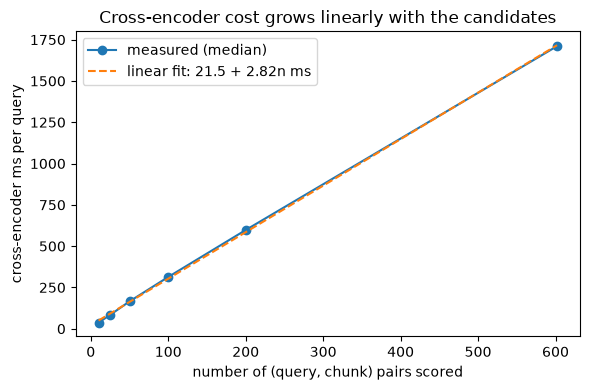

,median ms
n,
10,37.0
25,83.9
50,165.5
100,313.4
200,597.6
602,1710.8


In [49]:
# Cross-encoder time against the number of candidates n, for 3 queries: one warm-up and 5 timed runs per size.
sizes = [10, 25, 50, 100, 200, len(corpus)]
rows = []
for q in final_queries[:3]:
    order = index.search(bi_encoder.encode([q["query"]], normalize_embeddings=True), len(corpus))[1][0]
    for n in sizes:
        pairs = [(q["query"], corpus[i]["text"]) for i in order[:n]]     # the n best chunks by the bi-encoder
        cross_encoder.predict(pairs)                                     # warm-up
        for _ in range(5):
            start = time.perf_counter()
            cross_encoder.predict(pairs)
            rows.append({"qid": q["qid"], "n": n, "ms": (time.perf_counter() - start) * 1000})
ce_scaling = pd.DataFrame(rows).groupby("n")["ms"].median()
ms_per_pair, ce_intercept_ms = np.polyfit(ce_scaling.index, ce_scaling.values, 1)
ce_fit_ms = lambda n: ce_intercept_ms + ms_per_pair * n

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ce_scaling.index, ce_scaling.values, "o-", label="measured (median)")
ax.plot(ce_scaling.index, ce_fit_ms(ce_scaling.index), "--", label=f"linear fit: {ce_intercept_ms:.1f} + {ms_per_pair:.2f}n ms")
ax.set_xlabel("number of (query, chunk) pairs scored"); ax.set_ylabel("cross-encoder ms per query")
ax.set_title("Cross-encoder cost grows linearly with the candidates"); ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "artifacts/figures/ce_scaling.png", dpi=110)
plt.show()
ce_scaling.round(1).to_frame("median ms")


In [50]:
# Bi-encoder side: the query is encoded once whatever the corpus size; only the vector search grows with N.
# Exact search time against N, on random unit vectors of the same size (384). It is timed with numpy (all inner products,
# then the top 10), the same computation as IndexFlatIP: on this Mac, FAISS's multi-threaded search on large indexes
# crashes because torch and faiss each load their own OpenMP library.
rng = np.random.default_rng(CONFIG["seed"])
query_vector = bi_encoder.encode([final_queries[0]["query"]], normalize_embeddings=True)[0]
search_ms = {}
for n in [len(corpus), 10_000, 100_000, 200_000]:
    vectors = embeddings if n == len(corpus) else rng.standard_normal((n, embeddings.shape[1]), dtype=np.float32)
    vectors = vectors / np.linalg.norm(vectors, axis=1, keepdims=True)
    times = []
    for _ in range(20):
        start = time.perf_counter()
        scores = vectors @ query_vector
        top10 = np.argpartition(-scores, 10)[:10]
        times.append((time.perf_counter() - start) * 1000)
    search_ms[n] = np.median(times)
del vectors
search_ms_per_vector = search_ms[200_000] / 200_000

# Time per query for different corpus sizes: measured where we can, the rest extrapolated linearly from our numbers.
encode_ms = latency["encode_ms"].median()
rows = []
for n in [len(corpus), 100_000, 1_000_000, 10_000_000]:
    rows.append({"chunks N": f"{n:,}",
                 "cross-encoder on all N chunks (s)": ce_fit_ms(n) / 1000,
                 "two-stage: encode + exact search + CE on 10 (s)": (encode_ms + search_ms_per_vector * n + ce_ms) / 1000})
print("exact search, median ms:", {f"{n:,}": round(ms, 2) for n, ms in search_ms.items()})
print(f"cross-encoder fit: {ce_intercept_ms:.1f} + {ms_per_pair:.2f}n ms | query encoding: {encode_ms:.1f} ms (independent of N)")
pd.DataFrame(rows).set_index("chunks N").round(2)


exact search, median ms: {'602': np.float64(0.01), '10,000': np.float64(0.16), '100,000': np.float64(3.13), '200,000': np.float64(6.87)}
cross-encoder fit: 21.5 + 2.82n ms | query encoding: 4.8 ms (independent of N)


,cross-encoder on all N chunks (s),two-stage: encode + exact search + CE on 10 (s)
chunks N,,
602,1.72,0.04
"100,000",281.58,0.04
"1,000,000",2815.64,0.07
"10,000,000",28156.20,0.38


### 10.3 Quality check: the cross-encoder over all chunks

For each final query, the cross-encoder scores **all 602 chunks**. This shows what the bi-encoder stage costs in quality: can a full cross-encoder ranking find gold chunks that the top-10 pipeline missed (the recall-ceiling queries)? The table shows the queries whose result was not `both_ok`, with the best gold chunk's rank under each method.

In [51]:
# Quality check: what if the cross-encoder ranked ALL chunks for each final query (no bi-encoder stage)?
rows = []
start = time.perf_counter()
for q in final_queries:
    ce_scores = cross_encoder.predict([(q["query"], c["text"]) for c in corpus])
    bi_order = index.search(bi_encoder.encode([q["query"]], normalize_embeddings=True), len(corpus))[1][0]
    full_ce_ids = [corpus[i]["chunk_id"] for i in np.argsort(-ce_scores)]
    full_bi_ids = [corpus[i]["chunk_id"] for i in bi_order]
    rows.append({"qid": q["qid"], "result": result_of[q["qid"]],
                 "bi-encoder rank (all chunks)": min(full_bi_ids.index(g) + 1 for g in q["gold_essential"]),
                 "two-stage rank (CE on top 10)": metrics[(metrics.qid == q["qid"]) & (metrics.pipeline == "P2 re-rank")]["gold_rank"].iloc[0],
                 "CE rank (all chunks)": min(full_ce_ids.index(g) + 1 for g in q["gold_essential"])})
seconds = time.perf_counter() - start
full_ce = pd.DataFrame(rows)

print(f"{len(final_queries)} queries x {len(corpus)} chunks scored by the cross-encoder in {seconds:.0f} s")
print("Hit@3  two-stage:", round(metrics[metrics.pipeline == "P2 re-rank"]["hit@3"].mean(), 3),
      "| cross-encoder on all chunks:", round((full_ce["CE rank (all chunks)"] <= 3).mean(), 3))
full_ce[full_ce["result"] != "both_ok"].sort_values(["result", "qid"])


23 queries x 602 chunks scored by the cross-encoder in 48 s
Hit@3  two-stage: 0.696 | cross-encoder on all chunks: 0.739


,qid,result,bi-encoder rank (all chunks),two-stage rank (CE on top 10),CE rank (all chunks)
9,Q18,both_fail,6,6,20
17,Q34,both_fail,4,5,5
1,Q02,fixed_by_rerank,7,1,1
14,Q29,fixed_by_rerank,4,1,1
18,Q35,fixed_by_rerank,4,1,1
21,Q41,fixed_by_rerank,4,1,1
11,Q23,hurt_by_rerank,1,4,5
16,Q32,hurt_by_rerank,3,4,7
19,Q36,hurt_by_rerank,1,9,17
6,Q12,recall_ceiling,20,<NA>,1


## 11. Summary

### 11.1 Key numbers

Every value below is computed from the cells above.

In [52]:
p1, p2 = overall.loc["P1 baseline"], overall.loc["P2 re-rank"]
outcome = collections.Counter(result_of[q] for q in results)
count = lambda column, label: (answers[column] == label).sum()

key_numbers = {
    "document": CONFIG["doc"]["title"],
    "chunks in the frozen corpus (the same for both pipelines)": len(corpus),
    "final queries / candidate queries": f"{len(results)} / {len(queries)}",
    "fixed / hurt / both fail / recall ceiling / both ok": " / ".join(str(outcome[r]) for r in
        ["fixed_by_rerank", "hurt_by_rerank", "both_fail", "recall_ceiling", "both_ok"]),
    "Hit@3  P1 -> P2": f"{p1['Hit@3']:.3f} -> {p2['Hit@3']:.3f}",
    "MRR@10  P1 -> P2": f"{p1['MRR@10']:.3f} -> {p2['MRR@10']:.3f}",
    "correct answers  P1 -> P2": f"{count('Answer 1', 'correct')} -> {count('Answer 2', 'correct')}",
    "refusals  P1 -> P2": f"{count('Answer 1', 'refused')} -> {count('Answer 2', 'refused')}",
    "median retrieval ms  P1 -> P2": f"{latency['retrieval_p1_ms'].median():.1f} -> {latency['retrieval_p2_ms'].median():.1f}",
    "median end-to-end ms  P1 -> P2": f"{end_to_end_p1.median():.0f} -> {end_to_end_p2.median():.0f}",
    "re-rank overhead (median)": f"{ce_ms:.1f} ms = {100 * ce_ms / end_to_end_p2.median():.1f}% of end-to-end",
    "cross-encoder per (query, chunk) pair": f"{ms_per_pair:.2f} ms, so about {ms_per_pair * 1e6 / 60000:.0f} min per query for 1M chunks",
    "Hit@3 with the cross-encoder over all chunks": f"{(full_ce['CE rank (all chunks)'] <= 3).mean():.3f}",
}
pd.Series(key_numbers).to_frame("value")


,value
document,"Netrunner Comprehensive Rules v26.03 (Null Signal Games, effective 02 March 2026)"
chunks in the frozen corpus (the same for both pipelines),602
final queries / candidate queries,23 / 48
fixed / hurt / both fail / recall ceiling / both ok,4 / 3 / 2 / 2 / 12
Hit@3 P1 -> P2,0.652 -> 0.696
MRR@10 P1 -> P2,0.637 -> 0.687
correct answers P1 -> P2,15 -> 16
refusals P1 -> P2,7 -> 6
median retrieval ms P1 -> P2,4.8 -> 39.9
median end-to-end ms P1 -> P2,1327 -> 1803


**The failure categories named in the assignment** (ranks are bi-encoder -> cross-encoder; details in Sections 8.2 and 9):

| Category | Query that shows the baseline failing | Fixed by re-ranking? |
|---|---|---|
| At least two failure queries fixed | Q02, Q29, Q35, Q41 | yes, 4 queries (Answer 1 refused, Answer 2 correct) |
| Keyword trap | Q29: "flip face up" vs. the rule's word "rez", gold #4 -> #1 | yes |
| Buried at rank 4-10 | Q35 and Q41: gold #4 -> #1 | yes |
| Exception / corner case | Q12: gold at bi-encoder rank 20, outside the top 10 | no: recall ceiling (the cross-encoder over all chunks puts it at #1, Section 10.3) |
| Negation / constraint | Q18: rule 1.2.2 stays #6 -> #6 (full-corpus CE: #20); Q23: 3.8.5 #1 -> #7, while 10.3.1d #8 -> #4 | no |

None of the 7 exception and 10 negation candidates (Section 7.1) was fixed by re-ranking; this is reported as found, not forced.

### 11.2 Limitations

- **One document, a chosen query set.** 602 chunks of one rulebook. The 23 final queries were *selected* to include every query where re-ranking changed the outcome, so the metrics describe this set, not random questions. The full mining table for all 48 candidates is in Section 7.
- **Domain shift of the cross-encoder.** `ms-marco-MiniLM-L-6-v2` was trained on web search queries and passages; this document is formal rules text with numbered sub-rules and examples. The hurt cases in Section 9 show it can prefer fluent example text over terse rule lists.
- **LLM latency is noisy.** One call per query on the Gemini free tier; the network and Google's servers make p95 much larger than the median.
- **Hardware-specific timings.** All local timings come from one Mac (device in Section 1.3). The scaling numbers above 200,000 chunks are linear extrapolations, and approximate indexes (HNSW, IVF) were not measured.
- **Strict prompt.** With the refusal rule, a missing passage usually gives a refusal rather than a wrong answer, so retrieval failures show up as refusals (Section 8.4).

### 11.3 Change log

| When | Change | Re-run |
|---|---|---|
| Stage 5 | LLM switched from `gemini-3.6-flash` to `gemini-3.1-flash-lite` (free-tier limit of 20 requests per day), before any evaluation answer was generated | all answers generated with flash-lite |
| Stage 6 | Gold labels audited once with pooled judgement over all 10 candidates (Section 7.2); 6 queries changed, 3 apparent fixes removed | mining re-run on all 48 queries |
| Stage 6 | 23 final queries reviewed against the rule text, `expected_answer` added (one draft corrected: Q03) | no labels changed, nothing to re-run |
| Stage 8 | Scaling cell: exact search timed with numpy instead of FAISS for N up to 200,000 (FAISS crashed the kernel there because of two OpenMP libraries) | Section 10.2 only |

Chunking, models, `k` and the prompt did not change after the query set was frozen.